# MSAI6320 — Logistic Regression and Text Classification
## Unit 4 Lab: Triage Customer Messages for an Airline

**Course:** MSAI6320 — Natural Language Processing<br>
**Instructor:** Dr. Ahmed I. A. Shawahna | Birzeit University<br>
**Reference:** Jurafsky & Martin (2026), Chapter 4

---

### Objectives

By the end of this lab you will be able to:

1. Turn a message into features and compute $P(y=1|x)=\sigma(\mathbf{w}\cdot\mathbf{x}+b)$ by hand.
2. Implement the cross-entropy loss and its gradient, and verify the gradient numerically.
3. Train logistic regression with batch, stochastic and mini-batch gradient descent.
4. Extend the model to several classes with softmax.
5. Evaluate with per-class precision, recall and F1, and explain macro vs micro averaging.
6. Choose a decision threshold as a business decision, tune hyperparameters without touching the test set, and audit a model for unwanted behaviour.

### The story

You have just joined the customer-care ML team of an airline. Thousands of messages arrive on social media every day, and your manager has two requests:

- **An alert:** flag every message that *needs attention* (a complaint) so a person can reply quickly.
- **A triage model:** sort each message into *negative*, *neutral* or *positive*, so complaints, questions and thanks go to the right place.

Along the way a client will ask "why did the model say this?", and the business will ask you where to set the alert threshold. The lab ends with a team competition.

### How to use this notebook

- **Run cells in order, one at a time.** "Run All" stops at the first unfinished task, because its test fails on purpose.
- **Tasks:** look for `# YOUR CODE HERE` and replace the `raise NotImplementedError(...)` line with your code.
- **Tests:** the cell titled `# ✅ Test — Task N` follows each task. It prints `✅ Task N passed`, or an error message that points at the likely mistake.
- **Stuck?** Skip the failing test and keep going. Later cells detect an unfinished task, print a `⚠️` warning and use a library version instead, so being stuck on Task 3 does not stop you from doing Task 7.

### Outline

| § | Topic | You do |
|---|---|---|
| 0 | Setup and exploring the data | |
| 1 | Hand-crafted features and scaling | |
| 2 | The sigmoid and the binary classifier | Task 1 |
| 3 | Cross-entropy loss | Task 2 |
| 4 | The gradient and one step of descent | Task 3 |
| 5 | Batch, stochastic and mini-batch training | Task 4 |
| 6 | TF-IDF features at scale, interpretation, errors | |
| 7 | Multinomial logistic regression | Tasks 5, 6 |
| 8 | Evaluation and the alert threshold | Tasks 7, 8 |
| 9 | Regularization | |
| 10 | Dev sets and cross-validation | |
| 11 | Avoiding harms | |
| 12 | 🏆 Team competition | Task 9 |

---
## 0. Setup and Exploring the Data
*text classification and supervised learning.*

In [104]:
# ── Setup: run this cell first ────────────────────────────────────────────────
import os
import re
import sys
import time
import math
from pathlib import Path

# On Google Colab, the notebook does not start in its own folder, so we mount Drive
# and move into the folder that holds this notebook and its data folder.
# Edit COLAB_DIR to match your Drive location (sidebar → right-click folder → Copy path).
COLAB_DIR = "/content/drive/MyDrive/logistic_lab/"

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(COLAB_DIR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit, softmax as library_softmax
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import f1_score, log_loss, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline, make_union

# A fixed seed makes shuffling repeatable, so everyone in the room gets the same numbers.
SEED = 42
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.grid": True, "grid.alpha": 0.3})

DATA = Path("Data")
if not DATA.is_dir():
    raise FileNotFoundError(
        f"Cannot find the folder '{DATA}' in {Path.cwd()}.\n"
        "Put it in the same folder as this notebook. On Colab, check that COLAB_DIR "
        "above points to that folder (shared folder? use 'Add shortcut to Drive' first)."
    )
print(f"✅ Working folder: {Path.cwd()}")

CLASSES = ["negative", "neutral", "positive"]    # class index k = 0, 1, 2
_warned = set()


def with_fallback(task, student_fn, reference_fn, what):
    """Call student_fn; if the task is unfinished, warn once and call reference_fn instead."""
    def call(*args, **kwargs):
        try:
            return student_fn(*args, **kwargs)
        except NotImplementedError:
            if task not in _warned:
                print(f"⚠️  Task {task} is not finished yet: using {what} so the notebook can continue.")
                _warned.add(task)
            return reference_fn(*args, **kwargs)
    return call


def call_task(task, fn, *args, **kwargs):
    """Used by the tests: turn an unfinished task into a clear test failure."""
    try:
        return fn(*args, **kwargs)
    except NotImplementedError as error:
        raise AssertionError(f"Task {task} is not finished yet ({error}). "
                             "Complete it, re-run its cell, then re-run this test.") from None

✅ Working folder: /Users/Rayyan/Documents/Masters/NLP /Assignment 1


### The data

We use **Twitter US Airline Sentiment**: 14,640 real tweets to six US airlines from February 2015, each labelled negative, neutral or positive by human annotators. After removing 234 duplicates, we split the rest 70/15/15.

**Why remove duplicates?** A retweet in both train and test would be an exam question the model has already seen, and the score would be too high.

**Why a stratified split?** It keeps the class proportions the same in every split, so the scores are comparable.

**Why is the test set unlabelled?** Its labels are kept away from you so that nobody can tune on them. You tune on `dev`, and the leaderboard scores on `test`.

train: 10,084   dev: 2,161   test_public: 2,161 (no labels)


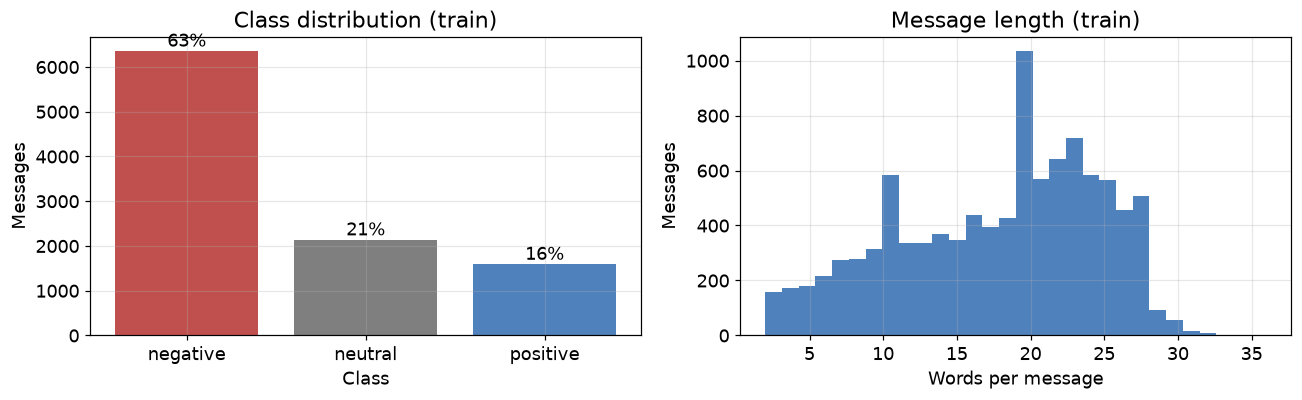

Median length: 19 words


In [105]:
# ── Load the local copies: no internet needed ─────────────────────────────────
train = pd.read_csv(DATA / "train.csv")
dev = pd.read_csv(DATA / "dev.csv")
test_public = pd.read_csv(DATA / "test_public.csv")

print(f"train: {len(train):,}   dev: {len(dev):,}   test_public: {len(test_public):,} (no labels)")

counts = train["label"].value_counts().reindex(CLASSES)
lengths = train["text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(CLASSES, counts.values, color=["#c0504d", "#7f7f7f", "#4f81bd"])
axes[0].set_title("Class distribution (train)")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Messages")
for i, n in enumerate(counts.values):
    axes[0].text(i, n, f"{n / len(train):.0%}", ha="center", va="bottom")
axes[1].hist(lengths, bins=30, color="#4f81bd")
axes[1].set_title("Message length (train)")
axes[1].set_xlabel("Words per message")
axes[1].set_ylabel("Messages")
plt.tight_layout()
plt.show()
print(f"Median length: {lengths.median():.0f} words")

In [106]:
# ── A few examples per class ──────────────────────────────────────────────────
# These are real tweets and some are rude. We skip those when printing in class;
# the training data itself is not changed.
RUDE = re.compile(r"f+u+c*k|sh[i1]t|bitch|\bass\b|asshole|\bdamn|\bcrap|\bwtf\b|\bstfu\b|\bhell\b|\bsuck", re.IGNORECASE)
polite = train[~train["text"].str.contains(RUDE)]

for label in CLASSES:
    print(f"\n── {label} ──")
    for text in polite[polite["label"] == label]["text"].sample(3, random_state=SEED):
        print("  ", text)

print(f"\nMessages containing 'Cancelled Flight': {train['text'].str.contains('Cancelled Flight').sum():,}")


── negative ──
   @united I paid for economy plus and you put me in the last boarding group so I have to gate check my bags too? @VirginAmerica knows better..
   @USAirways I'm trying to merge my freq flyer accts but keep getting an error message and only a machine when calling the # provided. Help!
   @JetBlue well, now I'll make sure to never fly JetBlue

── neutral ──
   @USAirways I understand that, and when I'm attempting to change the information so they are identical, it tells me to call a #
   @SouthwestAir to start daily #B737-700 flights from #Washington Reagan to #FtLauderdale on 8AUG #avgeek
   @united Thanks. UA1121, DEN, 40 min on tarmac.

── positive ──
   .@AmericanAir @TyWinter it's really the small things--the details--that make an excellent experience or a really irritating one.
   @SouthwestAir Thanks.
   @SouthwestAir thanks for your assistance..you guys ROCK!!💯

Messages containing 'Cancelled Flight': 709


**What this tells us.** Almost two in three messages are negative, and only about one in six is positive. A model that always says "negative" would already get 63% accuracy while being useless for two classes. This is why we will not rely on accuracy and why the competition uses macro-F1 (§8).

You may also spot odd phrases such as "Cancelled Flighting". The source data appears to have replaced forms of the word "cancel" with "Cancelled Flight". Real data has quirks like this, and it pays to look before modelling.

In [107]:
# ── Labels for the two products ───────────────────────────────────────────────
# Triage (multi-class): y = class index 0, 1, 2
# Alert  (binary):      y = 1 means "needs attention" (negative), y = 0 means everything else
to_index = {label: k for k, label in enumerate(CLASSES)}
y_tr_multi = train["label"].map(to_index).to_numpy()
y_dv_multi = dev["label"].map(to_index).to_numpy()
y_tr = (y_tr_multi == 0).astype(int)
y_dv = (y_dv_multi == 0).astype(int)

print(f"Alert: {y_tr.mean():.1%} of training messages need attention.")

Alert: 63.0% of training messages need attention.


> **Careful with signs.** In the slides $y=1$ means *positive review*, but in our alert $y=1$ means *needs attention*. Positive words will therefore get **negative** weights in our trained alert, the reverse of the slides. We chose this because the alert is what the manager asked for: the thing we want to detect is the class we call 1.

---
## 1. Hand-Crafted Features and Scaling

We start with the six features from the slides, because each weight is then easy to read:

| Feature | Definition |
|---|---|
| $x_1$ | count of positive lexicon words |
| $x_2$ | count of negative lexicon words |
| $x_3$ | 1 if "no" is in the message, else 0 |
| $x_4$ | count of first- and second-person pronouns |
| $x_5$ | 1 if "!" is in the message, else 0 |
| $x_6$ | $\ln(\text{word count})$ |

**Why log for length?** The jump from 5 to 10 words matters more than from 30 to 35; the log compresses long messages and keeps $x_6$ on a similar scale to the counts.

**Why this tokenizer?** It uses `re.findall` from the Regex lab. We keep inner hyphens and apostrophes so "second-rate" and "it's" stay whole, and keep punctuation as tokens because the slide does, which is how the review reaches 66 tokens and $\ln(66)=4.19$.

The lexicon in `data/sentiment_lexicon.csv` is a short list written for this lab, with some airline vocabulary such as "delayed" and "stranded".

In [108]:
# ── The lexicon and the six features ──────────────────────────────────────────
lexicon = pd.read_csv(DATA / "sentiment_lexicon.csv")
POS_WORDS = set(lexicon.loc[lexicon["polarity"] == "pos", "word"])
NEG_WORDS = set(lexicon.loc[lexicon["polarity"] == "neg", "word"])
PRONOUNS = {"i", "me", "my", "mine", "myself", "we", "us", "our", "ours", "ourselves",
            "you", "your", "yours", "yourself", "yourselves"}
FEATURE_NAMES = ["x1 positive words", "x2 negative words", "x3 has 'no'",
                 "x4 pronouns 1st/2nd", "x5 has '!'", "x6 ln(word count)"]


def tokenize(text):
    return re.findall(r"[\w'-]+|[^\w\s]", text.lower())


def extract_features(text):
    """Return the six slide features of one message as an array of shape [6]."""
    tokens = tokenize(text)
    return np.array([
        sum(t in POS_WORDS for t in tokens),
        sum(t in NEG_WORDS for t in tokens),
        float("no" in tokens),
        sum(t in PRONOUNS for t in tokens),
        float("!" in tokens),
        np.log(max(len(tokens), 1)),     # max(...) avoids log(0) on an empty message
    ], dtype=float)


# The review from the lecture slide.
SLIDE_REVIEW = ("It's hokey . There are virtually no surprises , and the writing is second-rate . "
                "So why was it so enjoyable ? For one thing , the cast is great . Another nice touch "
                "is the music . I was overcome with the urge to get off the couch and start dancing . "
                "It sucked me in , and it'll do the same to you .")
x_slide = extract_features(SLIDE_REVIEW)
print("Lecture slide expects x = [3, 2, 1, 3, 0, 4.19]")
print("We compute     x =", np.round(x_slide, 2).tolist())
assert np.allclose(x_slide, [3, 2, 1, 3, 0, np.log(66)])

X_tr_raw = np.vstack([extract_features(t) for t in train["text"]])
X_dv_raw = np.vstack([extract_features(t) for t in dev["text"]])
print("\nFeature matrix X: [m × f] =", X_tr_raw.shape)

Lecture slide expects x = [3, 2, 1, 3, 0, 4.19]
We compute     x = [3.0, 2.0, 1.0, 3.0, 0.0, 4.19]

Feature matrix X: [m × f] = (10084, 6)


### Scaling

When features have very different ranges, one learning rate cannot suit them all, so gradient descent is slow. The z-score fixes this: $x'_j=(x_j-\mu_j)/\sigma_j$ gives each feature mean 0 and standard deviation 1.

**Why compute $\mu$ and $\sigma$ on train only?** Using dev data to scale would leak information about data we pretend not to have seen. Dev messages are scaled with the *training* statistics.

In [109]:
# ── z-score scaling, fitted on train only ─────────────────────────────────────
mu = X_tr_raw.mean(axis=0)
sd = X_tr_raw.std(axis=0)
X_tr_hand = (X_tr_raw - mu) / sd
X_dv_hand = (X_dv_raw - mu) / sd      # same mu and sd, no refit

print(pd.DataFrame({"mean before": mu, "std before": sd, "mean after": X_tr_hand.mean(axis=0),
                    "std after": X_tr_hand.std(axis=0)}, index=FEATURE_NAMES).round(2))

                     mean before  std before  mean after  std after
x1 positive words           0.32        0.62         0.0        1.0
x2 negative words           0.56        0.82        -0.0        1.0
x3 has 'no'                 0.09        0.29        -0.0        1.0
x4 pronouns 1st/2nd         1.31        1.26         0.0        1.0
x5 has '!'                  0.22        0.41         0.0        1.0
x6 ln(word count)           3.03        0.45         0.0        1.0


---
## 2. The Sigmoid and the Binary Classifier

The score $z=\mathbf{w}\cdot\mathbf{x}+b$ can be any real number, so it is not a probability. The sigmoid squashes it into $(0,1)$:

$$\sigma(z)=\frac{1}{1+e^{-z}}$$

### Task 1 — A sigmoid that never breaks

**Task:** Complete `sigmoid`. It must work on a single number or an array, and stay finite for extreme scores.

**Why worry about extremes?** For $z=-1000$, $e^{-z}=e^{1000}$ is too large for a float: NumPy warns about overflow and produces `inf`. With many features and large weights, extreme scores can occur.

**Hint:** limit $z$ with `np.clip` before the exponential. A limit of ±500 is safe because $e^{500}$ still fits in a float, and $\sigma(\pm500)$ is already indistinguishable from 1 or 0.

In [110]:
def sigmoid(z):
    # Clip z to prevent exp() overflow
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [111]:
# ✅ Test — Task 1
result = call_task(1, sigmoid, 0.0)
assert np.isclose(result, 0.5), f"sigmoid(0) must be 0.5 but you returned {result}. Check the formula 1 / (1 + exp(-z))."
assert np.isclose(sigmoid(0.833), 0.6970, atol=1e-3), "sigmoid(0.833) should be about 0.697 (slide 33). Check the sign inside exp(-z)."
assert np.isclose(sigmoid(2.0) + sigmoid(-2.0), 1.0), "sigma(z) + sigma(-z) must equal 1 (slide 24). Check the formula."

values = sigmoid(np.array([-2.0, 0.0, 2.0]))
assert np.shape(values) == (3,), "sigmoid must work element by element on arrays. Use np.exp, not math.exp."
assert np.allclose(values, [0.1192, 0.5, 0.8808], atol=1e-3), "Wrong values on an array input."

with np.errstate(over="raise", invalid="raise"):
    try:
        extreme = sigmoid(np.array([-1000.0, 1000.0]))
    except FloatingPointError:
        raise AssertionError("Overflow at z = ±1000. Clip z before the exponential, e.g. np.clip(z, -500, 500).") from None
assert np.all(np.isfinite(extreme)), "sigmoid(±1000) must be finite, not NaN or inf."
assert np.allclose(extreme, [0.0, 1.0]), "sigmoid(-1000) should be about 0 and sigmoid(1000) about 1."
print("✅ Task 1 passed")

✅ Task 1 passed


z = w·x + b = 0.833        (slide 33: .833)
P(+|x) = σ(z)   = 0.70    (slide 33: 0.70)
P(-|x) = 1-σ(z) = 0.30    (slide 33: 0.30)
σ(-z)           = 0.30    (slide 24: 1-σ(z) = σ(-z))
Decision: z > 0, so ŷ = 1, i.e. positive (slides 25, 27)

Message: @united thanks for the great service, the crew was so nice!
x = [3.0, 0.0, 0.0, 0.0, 1.0, 2.64]
z = 11.447, P(+|x) = 1.000


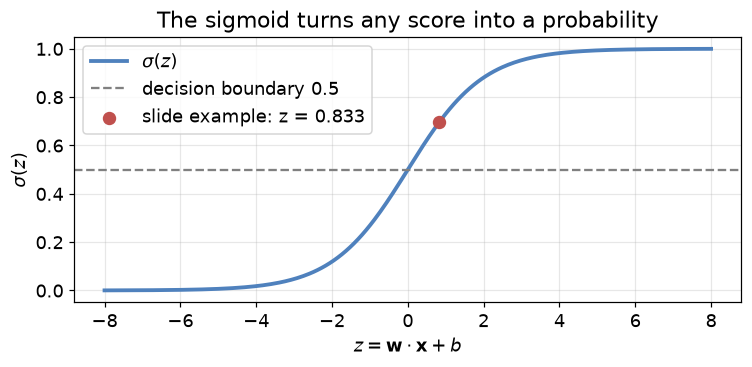

In [112]:
# ── Fallback, then the slide 32-33 example ────────────────────────────────────
sigmoid_safe = with_fallback(1, sigmoid, expit, "scipy's expit")

w_slide = np.array([2.5, -5.0, -1.2, 0.5, 2.0, 0.7])    # slide 32
b_slide = 0.1
z = w_slide @ x_slide + b_slide
p = sigmoid_safe(z)
print(f"z = w·x + b = {z:.3f}        (slide 33: .833)")
print(f"P(+|x) = σ(z)   = {p:.2f}    (slide 33: 0.70)")
print(f"P(-|x) = 1-σ(z) = {1 - p:.2f}    (slide 33: 0.30)")
print(f"σ(-z)           = {sigmoid_safe(-z):.2f}    (slide 24: 1-σ(z) = σ(-z))")
print(f"Decision: z > 0, so ŷ = {int(z > 0)}, i.e. positive (slides 25, 27)")

# The same slide weights on a real-style message. Here y=1 still means "positive", as in the slides.
message = "@united thanks for the great service, the crew was so nice!"
x_msg = extract_features(message)
z_msg = w_slide @ x_msg + b_slide
print(f"\nMessage: {message}\nx = {np.round(x_msg, 2).tolist()}")
print(f"z = {z_msg:.3f}, P(+|x) = {sigmoid_safe(z_msg):.3f}")

zs = np.linspace(-8, 8, 300)
plt.figure(figsize=(7, 3.5))
plt.plot(zs, sigmoid_safe(zs), lw=2.5, color="#4f81bd", label=r"$\sigma(z)$")
plt.axhline(0.5, color="gray", ls="--", label="decision boundary 0.5")
plt.scatter([z], [p], color="#c0504d", zorder=3, s=60, label=f"slide example: z = {z:.3f}")
plt.xlabel(r"$z=\mathbf{w}\cdot\mathbf{x}+b$")
plt.ylabel(r"$\sigma(z)$")
plt.title("The sigmoid turns any score into a probability")
plt.legend()
plt.tight_layout()
plt.show()

---
## 3. Cross-Entropy Loss

We choose $\mathbf{w},b$ to make the correct labels as probable as possible. Minimising the negative log of that probability gives the cross-entropy loss:

$$L_{CE}(\hat y,y)=-\left[y\log\hat y+(1-y)\log(1-\hat y)\right]$$

### Task 2 — Cross-entropy with clipping

**Task:** Complete `cross_entropy` so that it returns the **average** loss over all examples.

**Why average rather than sum?** The average does not grow with the number of messages, so the same learning rate works for any batch size.

**Why clip $\hat y$?** If $\hat y$ is exactly 0 or 1, $\log$ gives $-\infty$ and training breaks. Clipping into $[\epsilon,1-\epsilon]$ with $\epsilon=10^{-12}$ keeps the value finite, and is small enough not to change the loss on normal predictions.

In [113]:
def cross_entropy(y, y_hat, eps=1e-12):
    """Return the average binary cross-entropy (a single number).

    y:     true labels, shape [m], values 0 or 1
    y_hat: predicted P(y=1|x), shape [m]
    """
    y, y_hat = np.asarray(y, dtype=float), np.asarray(y_hat, dtype=float)
    # Clip y_hat to avoid log(0) which yields -inf
    y_hat = np.clip(y_hat, eps, 1 - eps)
    # Calculate the average cross entropy loss
    return np.mean(-(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat)))

In [114]:
# ✅ Test — Task 2
result = call_task(2, cross_entropy, np.array([1.0]), np.array([0.7]))
assert np.isclose(result, 0.3567, atol=1e-3), f"Loss for y=1, ŷ=0.7 should be -log(0.7) = 0.357 but you returned {result:.4f}. Use the natural log np.log and keep the minus sign."
result = cross_entropy(np.array([0.0]), np.array([0.7]))
assert np.isclose(result, 1.2040, atol=1e-3), f"Loss for y=0, ŷ=0.7 should be -log(0.3) = 1.204 but you returned {result:.4f}. Check the (1-y) log(1-ŷ) term."
result = cross_entropy(np.array([1.0, 0.0]), np.array([0.7, 0.7]))
assert np.isclose(result, (0.3567 + 1.2040) / 2, atol=1e-3), f"With two examples you should return the average, 0.780, but you returned {result:.4f}. Did you sum instead of averaging?"
with np.errstate(divide="ignore", invalid="ignore"):
    extreme = cross_entropy(np.array([1.0, 0.0]), np.array([0.0, 1.0]))
assert np.isfinite(extreme), "The loss is not finite when ŷ is exactly 0 or 1. Clip ŷ before taking the log."
assert extreme > 20, f"A confident wrong prediction should give a very large loss, but you returned {extreme:.2f}. Is eps too large?"
assert cross_entropy(np.array([1.0]), np.array([0.999])) < 0.01, "A confident correct prediction should give a loss close to 0."
print("✅ Task 2 passed")

✅ Task 2 passed


Slide 48: if the true y = 1, the loss is 0.36 (slide: .36)
Slide 49: if the true y = 0, the loss is 1.2 (slide: 1.2)

How much does being wrong cost? (true y = 1)
  ŷ = 0.99  loss = 0.01
  ŷ = 0.9   loss = 0.11
  ŷ = 0.7   loss = 0.36
  ŷ = 0.5   loss = 0.69
  ŷ = 0.3   loss = 1.20
  ŷ = 0.1   loss = 2.30
  ŷ = 0.01  loss = 4.61


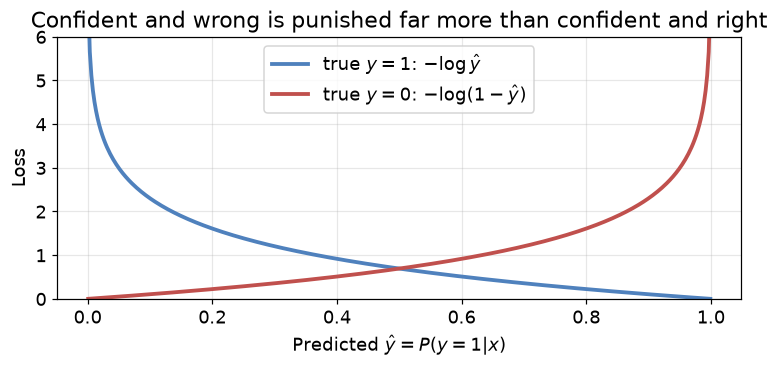

In [115]:
# ── Fallback, then the slide 48-50 example ────────────────────────────────────
cross_entropy_safe = with_fallback(2, cross_entropy,
                                   lambda y, y_hat, eps=1e-12: log_loss(y, np.clip(y_hat, eps, 1 - eps), labels=[0, 1]),
                                   "scikit-learn's log_loss")

print("Slide 48: if the true y = 1, the loss is", round(cross_entropy_safe(np.array([1.0]), np.array([0.70])), 2), "(slide: .36)")
print("Slide 49: if the true y = 0, the loss is", round(cross_entropy_safe(np.array([0.0]), np.array([0.70])), 1), "(slide: 1.2)")

print("\nHow much does being wrong cost? (true y = 1)")
for y_hat in [0.99, 0.9, 0.7, 0.5, 0.3, 0.1, 0.01]:
    print(f"  ŷ = {y_hat:<5} loss = {cross_entropy_safe(np.array([1.0]), np.array([y_hat])):.2f}")

grid = np.linspace(0.001, 0.999, 400)
plt.figure(figsize=(7, 3.5))
plt.plot(grid, -np.log(grid), lw=2.5, color="#4f81bd", label=r"true $y=1$: $-\log\hat y$")
plt.plot(grid, -np.log(1 - grid), lw=2.5, color="#c0504d", label=r"true $y=0$: $-\log(1-\hat y)$")
plt.xlabel(r"Predicted $\hat y=P(y=1|x)$")
plt.ylabel("Loss")
plt.ylim(0, 6)
plt.title("Confident and wrong is punished far more than confident and right")
plt.legend()
plt.tight_layout()
plt.show()

Moving from $\hat y=0.1$ to $0.01$ on a true positive adds about 2.3 to the loss, while moving from $0.99$ to $0.9$ adds only about 0.1. The loss pushes hardest on the examples the model is most wrong about.

---
## 4. The Gradient and One Step of Descent

The loss for logistic regression is **convex**: there is one minimum, so gradient descent can start anywhere. **We start from all zeros** because $\sigma(0)=0.5$ means the model begins with no preference for either class.

For one example, the slope for weight $w_j$ has a simple form:

$$\frac{\partial L_{CE}}{\partial w_j}=(\hat y-y)\,x_j\qquad\frac{\partial L_{CE}}{\partial b}=\hat y-y$$

For $m$ examples at once, we average:

$$\nabla_{\mathbf{w}}=\frac{1}{m}\mathbf{X}^{\top}(\hat{\mathbf{y}}-\mathbf{y})\qquad\nabla_{b}=\frac{1}{m}\sum_i(\hat y_i-y_i)$$

### A tool for checking gradients

A gradient bug can be silent: the code runs and the model simply trains badly. We can test any gradient from the definition of slope, by nudging one weight a tiny amount in each direction and watching the loss:

$$\frac{\partial L}{\partial w_j}\approx\frac{L(w_j+\epsilon)-L(w_j-\epsilon)}{2\epsilon}$$

**Why $\epsilon=10^{-5}$?** Much larger and the estimate is a poor approximation of the slope. Much smaller and floating-point rounding swamps the tiny difference. <br>**Why both directions?** The two-sided difference is much more accurate than a one-sided one.

In [116]:
def numeric_gradient(X, y, w, b, eps=1e-5):
    """Estimate the gradient from the definition of slope. Slow: for small checks only."""
    def loss(w_, b_):
        return cross_entropy_safe(y, sigmoid_safe(X @ w_ + b_))
    grad_w = np.zeros_like(w, dtype=float)
    for j in range(len(w)):
        step = np.zeros_like(w, dtype=float)
        step[j] = eps
        grad_w[j] = (loss(w + step, b) - loss(w - step, b)) / (2 * eps)
    grad_b = (loss(w, b + eps) - loss(w, b - eps)) / (2 * eps)
    return grad_w, grad_b

### Task 3 — The gradient

**Task:** Complete `gradient` using the formulas above. Write it with matrix products and no Python loop, so it also works on sparse matrices in §6.

**Hint:** first compute $\hat{\mathbf{y}}=\sigma(\mathbf{X}\mathbf{w}+b)$ with `sigmoid_safe` and call `error = y_hat - y`. Then `X.T @ error` gives the unaveraged $\mathbf{w}$ part.

In [117]:
def gradient(X, y, w, b):
    """Return (grad_w, grad_b), the gradient of the average cross-entropy.

    X: [m × f] matrix (dense or sparse)    y: [m]    w: [f]    b: a number
    grad_w: array of shape [f]             grad_b: a number
    """
    # YOUR CODE HERE
# calculate the gradients using matrix operations for efficiency
    m, _ = X.shape
    z = X @ w + b
    p = 1 / (1 + np.exp(-z))
    grad_w = (1/m) * X.T @ (p - y)
    grad_b = (1/m) * np.sum(p - y)
    return grad_w, grad_b


In [118]:
# ✅ Test — Task 3
# The slide 72-73 example: x = [3, 2], y = 1, all parameters 0.
grad_w, grad_b = call_task(3, gradient, np.array([[3.0, 2.0]]), np.array([1.0]), np.zeros(2), 0.0)
assert np.shape(grad_w) == (2,), f"grad_w must have shape [f] = (2,), but it has shape {np.shape(grad_w)}."
assert not np.allclose(grad_w, [1.5, 1.0]), "Your gradient has the wrong sign. It is (ŷ - y) x, not (y - ŷ) x."
assert np.allclose(grad_w, [-1.5, -1.0]), f"Slide 73 gives grad_w = [-1.5, -1.0], but you returned {grad_w}."
assert np.isclose(grad_b, -0.5), f"Slide 73 gives grad_b = -0.5, but you returned {grad_b}. Did you forget the bias?"

# Must average over the batch, not sum.
X_toy = np.array([[1.0, 2.0], [3.0, -1.0], [-2.0, 1.0], [0.0, 1.0]])
y_toy = np.array([1.0, 0.0, 1.0, 0.0])
grad_w, grad_b = gradient(X_toy, y_toy, np.zeros(2), 0.0)
assert np.allclose(grad_w, [0.5, -0.375]), f"Expected [0.5, -0.375] on 4 examples, got {grad_w}. Did you sum instead of averaging?"
assert np.isclose(grad_b, 0.0), f"Expected grad_b = 0 here, got {grad_b}."

# Must match finite differences at a point that is not zero.
w_test, b_test = np.array([0.3, -0.7]), 0.2
grad_w, grad_b = gradient(X_toy, y_toy, w_test, b_test)
num_w, num_b = numeric_gradient(X_toy, y_toy, w_test, b_test)
assert np.allclose(grad_w, num_w, atol=1e-5), f"grad_w differs from finite differences: {grad_w} vs {num_w}. Does ŷ use b as well as w?"
assert np.isclose(grad_b, num_b, atol=1e-5), f"grad_b differs from finite differences: {grad_b} vs {num_b}."
print("✅ Task 3 passed (gradient check agrees with finite differences)")

✅ Task 3 passed (gradient check agrees with finite differences)


In [119]:
# ── Fallback, then one step of gradient descent: slides 72-74 ─────────────────
gradient_safe = with_fallback(3, gradient, numeric_gradient, "the finite-difference estimate")

X_one = np.array([[3.0, 2.0]])     # x1 = 3 positive words, x2 = 2 negative words
y_one = np.array([1.0])            # a positive review
w0, b0, eta = np.zeros(2), 0.0, 0.1

grad_w, grad_b = gradient_safe(X_one, y_one, w0, b0)
w1, b1 = w0 - eta * grad_w, b0 - eta * grad_b

print("Gradient  =", np.round(np.r_[grad_w, grad_b], 2).tolist(), "   (slide 73: [-1.5, -1.0, -0.5])")
print("θ1 = θ0 - η·gradient =", np.round(np.r_[w1, b1], 2).tolist(), "   (slide 74: [.15, .1, .05])")
print("\nw2 went up even though x2 counts negative words: this one example is positive.")
print("Enough negative examples would eventually push w2 below zero (slide 74).")

Gradient  = [-1.5, -1.0, -0.5]    (slide 73: [-1.5, -1.0, -0.5])
θ1 = θ0 - η·gradient = [0.15, 0.1, 0.05]    (slide 74: [.15, .1, .05])

w2 went up even though x2 counts negative words: this one example is positive.
Enough negative examples would eventually push w2 below zero (slide 74).


---
## 5. Batch, Stochastic and Mini-Batch Training

The three variants differ only in how many examples are used for each gradient:

| Variant | Examples per update | Behaviour |
|---|---|---|
| Stochastic (SGD) | 1 | many cheap, noisy updates |
| Batch | all $m$ | one accurate, expensive update per pass |
| Mini-batch | a small group | fast vectorized updates with moderate noise |

### Task 4 — The update rule

The loop below is written for you: it shuffles each epoch, so that batches differ from one pass to the next, and cuts the data into mini-batches. Only the heart of training is missing.

**Task:** For the current mini-batch `Xb, yb`, compute the gradient and update `w` and `b`:

$$\theta^{t+1}=\theta^{t}-\eta_k\nabla L$$

Use `gradient(...)` and the current learning rate `eta_k`. The `apply_penalty` line is regularization: ignore it until §9, as it does nothing while `alpha = 0`.

**What a correct result looks like:** after this task, the next training cell should report a final training loss of about 0.49.

In [120]:
def apply_penalty(w, eta, alpha, penalty, m):
    """Shrink the weights for L2 or L1 regularization. Explained in §9; does nothing when alpha = 0."""
    if alpha == 0:
        return w
    if penalty == "l2":
        return w - eta * 2 * alpha / m * w
    shrink = eta * alpha / m                                # L1
    return np.sign(w) * np.maximum(np.abs(w) - shrink, 0)


def train_logreg(X, y, eta=0.1, epochs=20, batch_size=64, alpha=0.0, penalty="l2", decay=0.0,
                 X_dev=None, y_dev=None, seed=SEED):
    """Train binary logistic regression from scratch. Returns (w, b, history).

    decay slowly lowers the learning rate, eta_k = eta / (1 + decay * epoch).
    """
    m, f = X.shape
    w, b = np.zeros(f), 0.0
    rng = np.random.default_rng(seed)
    history = {"train_loss": [], "dev_loss": []}

    for epoch in range(epochs):
        eta_k = eta / (1 + decay * epoch)
        order = rng.permutation(m)
        for start in range(0, m, batch_size):
            batch = order[start:start + batch_size]
            Xb, yb = X[batch], y[batch]
            grad_w, grad_b = gradient(Xb, yb, w, b)
            w -= eta_k * grad_w
            b -= eta_k * grad_b
            w = apply_penalty(w, eta_k, alpha, penalty, m)

        history["train_loss"].append(cross_entropy_safe(y, sigmoid_safe(X @ w + b)))
        if X_dev is not None:
            history["dev_loss"].append(cross_entropy_safe(y_dev, sigmoid_safe(X_dev @ w + b)))
    return w, b, history

In [121]:
# ✅ Test — Task 4
X_toy = np.array([[1.0, 2.0], [3.0, -1.0], [-2.0, 1.0], [0.0, 1.0]])
y_toy = np.array([1.0, 0.0, 1.0, 0.0])

# One full-batch step from zero is deterministic: w = 0 - 0.5 * [0.5, -0.375] = [-0.25, 0.1875].
w_t, b_t, hist = call_task(4, train_logreg, X_toy, y_toy, eta=0.5, epochs=1, batch_size=4)
assert not np.allclose(w_t, [0.25, -0.1875]), "w moved uphill. Gradient descent subtracts: w = w - eta * grad."
assert np.allclose(w_t, [-0.25, 0.1875]), f"After one full-batch step w should be [-0.25, 0.1875], got {w_t}."

# The bias must be updated too: with all y = 1 the bias must rise from 0.
_, b_t, _ = train_logreg(X_toy, np.ones(4), eta=0.5, epochs=1, batch_size=4)
assert np.isclose(b_t, 0.25), f"With all y = 1, b should become 0.25, got {b_t}. Did you forget to update b?"

# The loss must fall during training.
rng = np.random.default_rng(0)
X_big = rng.normal(size=(300, 3))
y_big = (X_big @ np.array([1.5, -2.0, 0.5]) + rng.normal(size=300) > 0).astype(float)
w_t, b_t, hist = train_logreg(X_big, y_big, eta=0.1, epochs=30, batch_size=16)
assert hist["train_loss"][-1] < hist["train_loss"][0], "The training loss did not fall. Check the sign of your update."
assert hist["train_loss"][-1] < 0.50, f"The final loss should be below 0.50, got {hist['train_loss'][-1]:.3f}. Are you using the mini-batch (Xb, yb)?"

# Must agree with scikit-learn. A huge C means almost no regularization.
sk = LogisticRegression(C=1e6, max_iter=1000).fit(X_big, y_big)
w_t, b_t, _ = train_logreg(X_big, y_big, eta=1.0, epochs=1500, batch_size=300)
assert np.allclose(w_t, sk.coef_[0], atol=0.05), f"After long training w should match scikit-learn: {np.round(w_t, 3)} vs {np.round(sk.coef_[0], 3)}."
print("✅ Task 4 passed")

✅ Task 4 passed


In [122]:
# ── A library fallback, then train the alert on the six features ──────────────
def _reference_train(X, y, eta=0.1, epochs=20, batch_size=64, alpha=0.0, penalty="l2", decay=0.0,
                     X_dev=None, y_dev=None, seed=SEED):
    """Library stand-in for an unfinished Task 3 or 4. SGDClassifier is always one example at a time."""
    m = X.shape[0]
    clf = SGDClassifier(loss="log_loss", penalty=penalty, alpha=(2 * alpha if penalty == "l2" else alpha) / m,
                        learning_rate="constant", eta0=eta / batch_size, random_state=seed)
    history = {"train_loss": [], "dev_loss": []}
    for _ in range(epochs):
        clf.partial_fit(X, y, classes=[0, 1])
        history["train_loss"].append(log_loss(y, clf.predict_proba(X), labels=[0, 1]))
        if X_dev is not None:
            history["dev_loss"].append(log_loss(y_dev, clf.predict_proba(X_dev), labels=[0, 1]))
    return clf.coef_[0].copy(), float(clf.intercept_[0]), history

train_safe = with_fallback(4, train_logreg, _reference_train, "scikit-learn's SGDClassifier")


def alert_f1(X, y, w, b):
    """Macro-F1 of the alert with the decision boundary at 0.5."""
    return f1_score(y, (sigmoid_safe(X @ w + b) >= 0.5).astype(int), average="macro")


# Why eta = 0.1 and batch_size = 64? The features are scaled, so 0.1 is a sensible starting step
# (the sweep below tests it). Slide 75 mentions batches of 512+ for large data; our 10,000
# messages are few enough that 64 gives many updates per pass.
w_hand, b_hand, hist = train_safe(X_tr_hand, y_tr, eta=0.1, epochs=20, batch_size=64,
                                  X_dev=X_dv_hand, y_dev=y_dv)

print(f"Loss: start log 2 = {np.log(2):.3f}, final train = {hist['train_loss'][-1]:.3f}, final dev = {hist['dev_loss'][-1]:.3f}")
print(f"Alert macro-F1 on dev: {alert_f1(X_dv_hand, y_dv, w_hand, b_hand):.3f}\n")
for name, weight in zip(FEATURE_NAMES, w_hand):
    print(f"  {name:<22} w = {weight:+.2f}")
print(f"  {'bias':<22} b = {b_hand:+.2f}")

Loss: start log 2 = 0.693, final train = 0.485, final dev = 0.484
Alert macro-F1 on dev: 0.712

  x1 positive words      w = -0.64
  x2 negative words      w = +1.19
  x3 has 'no'            w = +0.40
  x4 pronouns 1st/2nd    w = +0.18
  x5 has '!'             w = -0.23
  x6 ln(word count)      w = +0.51
  bias                   b = +0.87


**Why do we start at $\log 2$?** At $\mathbf{w}=0,\,b=0$ every $\hat y$ is 0.5, and $-\log 0.5=0.693$.

**Reading the weights.** More negative words push strongly toward "needs attention" ($x_2$), and positive words push away ($x_1$), the reverse of the slide signs because $y=1$ here means a complaint. Longer messages and "no" also point to a complaint, while "!" points slightly away. Each weight is per standard deviation of its feature, because we scaled the inputs. Six features reach a macro-F1 of about 0.71, which is a decent start.

Stochastic (1)   updates =  60000   final loss = 0.510   time = 0.49 s
Mini-batch (64)  updates =    940   final loss = 0.491   time = 0.01 s
Batch (3000)     updates =     20   final loss = 0.573   time = 0.00 s


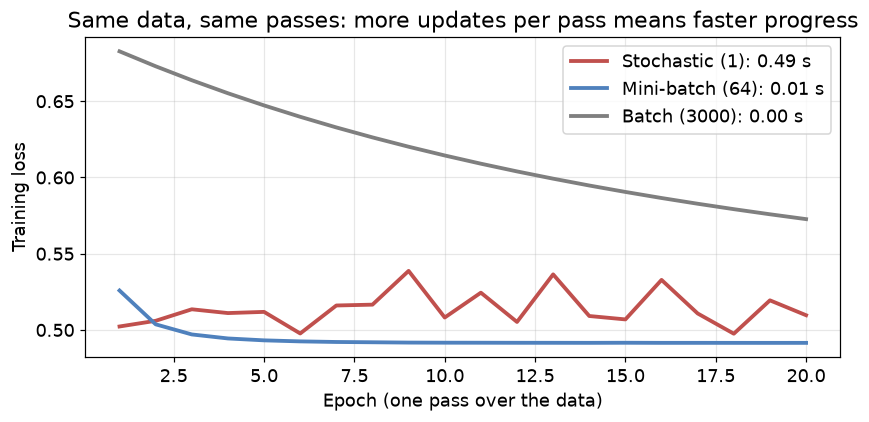

In [123]:
# ── Compare the three variants ────────────────────────────────────────────────
# We use 3,000 messages here because pure SGD runs one Python step per message, and
# that is enough to show the difference. All variants get the same 20 passes.
X_small, y_small = X_tr_hand[:3000], y_tr[:3000]

fig, ax = plt.subplots(figsize=(8, 4))
for name, batch_size, color in [("Stochastic (1)", 1, "#c0504d"), ("Mini-batch (64)", 64, "#4f81bd"), ("Batch (3000)", 3000, "#7f7f7f")]:
    start = time.perf_counter()
    w_v, b_v, h = train_safe(X_small, y_small, eta=0.1, epochs=20, batch_size=batch_size)
    seconds = time.perf_counter() - start
    ax.plot(range(1, 21), h["train_loss"], lw=2.5, color=color, label=f"{name}: {seconds:.2f} s")
    print(f"{name:<16} updates = {20 * int(np.ceil(3000 / batch_size)):>6}   final loss = {h['train_loss'][-1]:.3f}   time = {seconds:.2f} s")
ax.set_xlabel("Epoch (one pass over the data)")
ax.set_ylabel("Training loss")
ax.set_title("Same data, same passes: more updates per pass means faster progress")
ax.legend()
plt.tight_layout()
plt.show()

Batch gradient descent makes only 20 updates, so after 20 passes it is still far from the minimum (loss 0.57). SGD makes 60,000 updates and takes far longer than mini-batch, yet ends with a slightly worse loss (0.51 vs 0.49), because it is still bouncing around the minimum with noisy steps at this learning rate. Mini-batch combines good progress with vectorized speed, which is why it is the usual choice.

η = 0.001  final training loss = 0.541
η = 0.01   final training loss = 0.485
η = 0.1    final training loss = 0.485
η = 1.0    final training loss = 0.490
η = 10.0   final training loss = 0.612


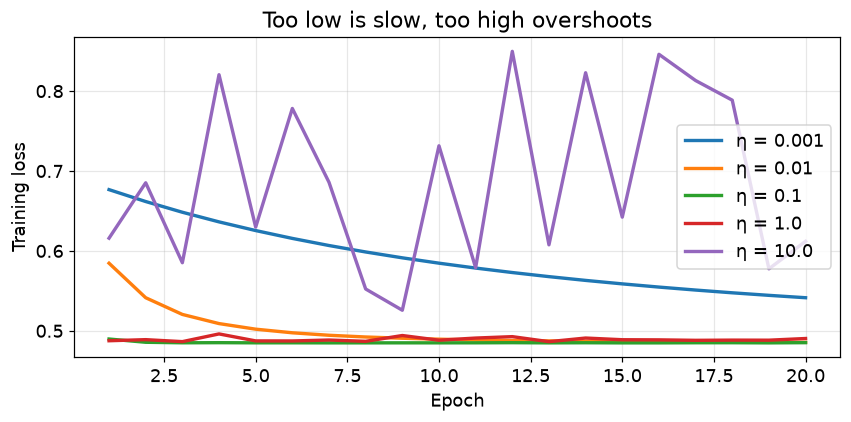

In [124]:
# ── Choosing the learning rate (slide 69) ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
for eta_try in [0.001, 0.01, 0.1, 1.0, 10.0]:
    _, _, h = train_safe(X_tr_hand, y_tr, eta=eta_try, epochs=20, batch_size=64)
    ax.plot(range(1, 21), h["train_loss"], lw=2.2, label=f"η = {eta_try}")
    print(f"η = {eta_try:<6} final training loss = {h['train_loss'][-1]:.3f}")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training loss")
ax.set_title("Too low is slow, too high overshoots")
ax.legend()
plt.tight_layout()
plt.show()

At η = 0.001 the steps are too small to finish in 20 epochs, and at η = 10 they overshoot and the loss ends much higher. Between 0.01 and 1 the results are close, so we keep 0.1. We try values a factor of 10 apart because at first we only need the right order of magnitude. A common refinement is to start high and slowly decrease the rate, which is what `decay` does for the larger models below.

**When do we stop?** When the gradient is close to zero, or when the loss starts rising on a held-out set. We use a fixed number of epochs to keep runtimes predictable in class, and check the dev loss to confirm it was enough.

---
## 6. TF-IDF Features at Scale, Interpretation and Errors

Six features cannot capture much. A natural next step is to let every word in the vocabulary be a feature, with a weight learned per word.

We could use raw word counts, but words like "the" are frequent everywhere and say little. **TF-IDF** gives each word in a message a value that combines two ideas:

$$\text{tf-idf}(t,d)=\underbrace{\text{count of word } t \text{ in message } d}_{\text{tf: frequent in this message}}\times\underbrace{\log\frac{\text{number of messages}}{\text{number of messages containing } t}}_{\text{idf: rare across messages}}$$

So a word scores high when it is frequent in this message and rare overall. Scikit-learn's `TfidfVectorizer` uses a smoothed version of this formula and then scales each message's vector to length 1, so long messages do not get larger scores just for being long.

**Why learn the vocabulary and idf on train only?** The same reason as z-scoring: dev must stay unseen.<br>**Why `min_df=2`?** A word seen in only one training message gives no evidence of a general pattern.<br>**Why sparse matrices?** Each message uses only a few of the thousands of words, so storing only the non-zero values saves memory and time.

In [125]:
# ── Build the features ────────────────────────────────────────────────────────
vectorizer = TfidfVectorizer(min_df=2)
X_tr = vectorizer.fit_transform(train["text"])
X_dv = vectorizer.transform(dev["text"])
vocab = vectorizer.get_feature_names_out()

print(f"X: [m × f] = {X_tr.shape}")
print(f"Non-zero values: {X_tr.nnz:,} of {X_tr.shape[0] * X_tr.shape[1]:,} ({X_tr.nnz / (X_tr.shape[0] * X_tr.shape[1]):.2%})")

example = "my flight was delayed again"
row = vectorizer.transform([example])
print(f"\nTF-IDF of: '{example}'")
for j in row.nonzero()[1][np.argsort(-row.data)]:
    print(f"  {vocab[j]:<10} {row[0, j]:.3f}")

X: [m × f] = (10084, 5105)
Non-zero values: 154,827 of 51,478,820 (0.30%)

TF-IDF of: 'my flight was delayed again'
  again      0.582
  delayed    0.539
  was        0.412
  my         0.329
  flight     0.305


Notice that "delayed" scores above common words such as "my" and "was".

### From scratch vs scikit-learn: why $C=1/(2\alpha)$

Scikit-learn has no $\alpha$. It minimises $\frac{1}{2}\|\mathbf{w}\|^2+C\sum_i L_{CE}^{(i)}$. The slides maximise the log-likelihood minus $\alpha\sum_j\theta_j^2$, which is the same as minimising $\sum_i L_{CE}^{(i)}+\alpha\|\mathbf{w}\|^2$. Dividing scikit-learn's objective by $C$ gives $\sum_i L_{CE}^{(i)}+\frac{1}{2C}\|\mathbf{w}\|^2$, so the two match when

$$C=\frac{1}{2\alpha}\qquad\text{(L2)}$$

You will often see "$C=1/\lambda$". That is the same fact written for a penalty of $\frac{\lambda}{2}\|\mathbf{w}\|^2$, so $\lambda=2\alpha$. A large $C$ means a small penalty. §9 explains regularization itself; here it just gives both models the same objective, which is why we can expect them to agree. We use $\alpha=0.5$, which is $C=1$, scikit-learn's default.

In [126]:
# ── Train from scratch on sparse features, then compare with scikit-learn ─────
ALPHA = 0.5

# Why eta = 5.0? TF-IDF rows have length 1, so the gradients are small and a larger step is fine.
# Why decay? It takes big steps early and small steps late, so the mini-batch noise settles.
start = time.perf_counter()
w_tfidf, b_tfidf, hist = train_safe(X_tr, y_tr, eta=5.0, epochs=30, batch_size=64, alpha=ALPHA, decay=0.1,
                                    X_dev=X_dv, y_dev=y_dv)
print(f"From scratch: {time.perf_counter() - start:.1f} s, final train loss {hist['train_loss'][-1]:.3f}, dev loss {hist['dev_loss'][-1]:.3f}")

start = time.perf_counter()
sk_alert = LogisticRegression(C=1 / (2 * ALPHA), max_iter=2000).fit(X_tr, y_tr)
print(f"scikit-learn: {time.perf_counter() - start:.1f} s")

agree = np.mean((sigmoid_safe(X_dv @ w_tfidf + b_tfidf) >= 0.5) == sk_alert.predict(X_dv))
cosine = w_tfidf @ sk_alert.coef_[0] / (np.linalg.norm(w_tfidf) * np.linalg.norm(sk_alert.coef_[0]))

print(f"\n{'Alert model':<34}{'dev macro-F1':>13}")
print(f"{'Six hand-crafted features':<34}{alert_f1(X_dv_hand, y_dv, w_hand, b_hand):>13.3f}")
print(f"{'TF-IDF, from scratch':<34}{alert_f1(X_dv, y_dv, w_tfidf, b_tfidf):>13.3f}")
print(f"{'TF-IDF, scikit-learn':<34}{f1_score(y_dv, sk_alert.predict(X_dv), average='macro'):>13.3f}")
print(f"\nFrom scratch vs scikit-learn: same prediction on {agree:.1%} of dev, weight cosine similarity {cosine:.3f}")

From scratch: 0.3 s, final train loss 0.337, dev loss 0.396
scikit-learn: 0.0 s

Alert model                        dev macro-F1
Six hand-crafted features                 0.712
TF-IDF, from scratch                      0.812
TF-IDF, scikit-learn                      0.817

From scratch vs scikit-learn: same prediction on 98.8% of dev, weight cosine similarity 0.996


Letting every word be a feature lifts the alert from about 0.71 to about 0.81. The from-scratch model and scikit-learn make the same prediction on nearly 99% of dev messages, with almost the same weight direction. They are not identical because our loop stops after a fixed number of epochs, while scikit-learn runs a faster specialised solver until convergence.

### "Why did the model say this?"

A client complains that a thank-you message was flagged. Logistic regression can answer directly, because $z$ is just a sum: each word contributes $w_j x_j$.

In [127]:
# ── The words that matter most, overall ───────────────────────────────────────
ranked = np.argsort(w_tfidf)
display_rude = lambda word: bool(RUDE.search(word))
def top_words(indices, n=12):
    return [vocab[j] for j in indices if not display_rude(vocab[j])][:n]
print("Most toward 'needs attention':", ", ".join(top_words(ranked[::-1])))
print("Most away from it:            ", ", ".join(top_words(ranked)))


# ── One prediction, explained as a sum ────────────────────────────────────────
def explain(text, w, b, n=8):
    row = vectorizer.transform([text]).tocsr()
    words = [(vocab[j], x, w[j], w[j] * x) for j, x in zip(row.indices, row.data)]
    words.sort(key=lambda item: -abs(item[3]))
    print(f"Message: {text}\n")
    print(f"{'word':<14}{'x (tf-idf)':>11}{'w':>9}{'w·x':>9}")
    for word, x, weight, part in words[:n]:
        print(f"{word:<14}{x:>11.3f}{weight:>9.2f}{part:>+9.2f}")
    total = sum(item[3] for item in words)
    print(f"{'(other words)':<14}{'':>11}{'':>9}{sum(item[3] for item in words[n:]):>+9.2f}")
    print(f"{'bias b':<14}{'':>11}{'':>9}{b:>+9.2f}")
    print(f"\nz = {total + b:+.2f}, P(needs attention) = {sigmoid_safe(total + b):.3f}")

print()
explain("@united thanks but my flight was delayed again and nobody helped", w_tfidf, b_tfidf)

Most toward 'needs attention': not, no, hours, delayed, hold, worst, why, cancelled, because, your, hour, delay
Most away from it:             thank, thanks, southwestair, jetblue, great, virginamerica, love, amazing, awesome, best, kudos, worries

Message: @united thanks but my flight was delayed again and nobody helped

word           x (tf-idf)        w      w·x
thanks              0.251    -5.62    -1.41
delayed             0.300     3.99    +1.20
again               0.324     1.96    +0.64
but                 0.240     2.61    +0.63
and                 0.170     1.85    +0.32
my                  0.183     1.49    +0.27
nobody              0.533     0.29    +0.15
flight              0.170     0.77    +0.13
(other words)                         -0.13
bias b                                -0.18

z = +1.62, P(needs attention) = 0.835


In [128]:
# ── Error analysis: where is the alert most confidently wrong? ────────────────
p_dv = sigmoid_safe(X_dv @ w_tfidf + b_tfidf)
polite_dev = ~dev["text"].str.contains(RUDE).to_numpy()

false_alarms = np.where((y_dv == 0) & (p_dv >= 0.5) & polite_dev)[0]
missed = np.where((y_dv == 1) & (p_dv < 0.5) & polite_dev)[0]

print("False alarms: flagged, but gold says no attention needed")
for i in false_alarms[np.argsort(-p_dv[false_alarms])][:5]:
    print(f"  P = {p_dv[i]:.2f} [{dev['label'].iloc[i]}] {dev['text'].iloc[i]}")
print("\nMissed complaints: gold says needs attention, but not flagged")
for i in missed[np.argsort(p_dv[missed])][:5]:
    print(f"  P = {p_dv[i]:.2f} {dev['text'].iloc[i]}")

False alarms: flagged, but gold says no attention needed
  P = 0.98 [neutral] @united I tried.   We were hung up on, twice. After speaking with someone, then put on hold for 45 minutes.  No resolution.
  P = 0.97 [neutral] @USAirways a $75 change is ok most of the time but if there r open seats on earlier flt and no chkd bag, why not let someone fly standby?
  P = 0.95 [neutral] @AmericanAir You don't have those abilities anywhere! Not at the ticket counter, at cust service, or online. That's why we're done here.
  P = 0.95 [positive] @USAirways still not in the air for deicing of plane. I'll miss connect but customer service was helpful.I'm hoping to catch the next flight
  P = 0.94 [neutral] @SouthwestAir I was under the impression when there is an 8 hour delay in your flight because of equipment failure, compensation is offered?

Missed complaints: gold says needs attention, but not flagged
  P = 0.08 @united I know that. Thanks for the standard reply.
  P = 0.09 @SouthwestAir Thank

**What the errors show.** Several false alarms look like real complaints that annotators marked neutral ("hung up on, twice"), so some "errors" are really debatable labels. Sarcasm defeats a model that only counts words: "thank you for 7 hrs at terminal D" is scored as thanks. Mixed messages pull both ways. Each pattern suggests something to try in the competition, and this loop of inspecting errors and refining features is the one slides describe.

Also look back at the word list: the airline names `southwestair`, `jetblue` and `virginamerica` lean away from an alert. The model has learned which airlines receive fewer complaints, not anything about the message. We return to this in §11.

---
## 7. Multinomial Logistic Regression

The manager's second request needs three classes, so one weight vector is not enough. We now use one per class, $K$ of them, stacked in a weight matrix $\mathbf{W}$ of shape $[K\times f]$, plus a bias vector $\mathbf{b}$ of shape $[K]$. Each class gets a score $z_k=\mathbf{w}_k\cdot\mathbf{x}+b_k$, and **softmax** turns the scores into probabilities that sum to 1:

$$\hat y_k=\frac{\exp(z_k)}{\sum_{j=1}^{K}\exp(z_j)}$$

### Task 5 — A stable softmax

**Task:** Complete `softmax` for a matrix of scores, with one row per message.

**Why stabilise it?** With a score of 1000, `exp` overflows. Subtracting the largest score in each row first fixes this without changing the answer: $e^{z_k-c}/\sum_j e^{z_j-c}=e^{z_k}/\sum_j e^{z_j}$ because the $e^{-c}$ cancels.

**Hint:** use `axis=1` with `keepdims=True` in both the `max` and the `sum`, so each row is handled on its own.

In [129]:
def softmax(Z):
    """Return probabilities from scores.

    Z: [m × K] scores, one row per message.    Returns [m × K], each row summing to 1.
    """
    Z = np.asarray(Z, dtype=float)
    # YOUR CODE HERE
    # Subtract the max for numerical stability
    Z_max = np.max(Z, axis=1, keepdims=True)
    exp_Z = np.exp(Z - Z_max)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

In [130]:
# ✅ Test — Task 5
result = call_task(5, softmax, np.array([[1.0, 2.0, 3.0]]))
assert np.shape(result) == (1, 3), f"Output must have the same shape as the input, (1, 3), but has {np.shape(result)}."
assert np.allclose(result, [[0.0900, 0.2447, 0.6652]], atol=1e-3), f"softmax([1, 2, 3]) should be [0.090, 0.245, 0.665], got {np.round(result, 3)}."

two_rows = softmax(np.array([[0.0, 0.0, 0.0], [5.0, 1.0, -2.0]]))
assert np.allclose(two_rows.sum(axis=1), 1.0), "Each ROW must sum to 1. Check axis=1 and keepdims=True."
assert np.allclose(two_rows[0], 1 / 3), "Equal scores must give equal probabilities, 1/3 each. Are you using a max over the whole matrix?"
assert np.allclose(two_rows[1], [0.98114, 0.01797, 0.00089], atol=1e-3), f"Second row should be [0.981, 0.018, 0.001], got {np.round(two_rows[1], 3)}."

with np.errstate(over="raise", invalid="raise"):
    try:
        extreme = softmax(np.array([[1000.0, 0.0, -1000.0]]))
    except FloatingPointError:
        raise AssertionError("Overflow on scores of ±1000. Subtract each row's max before the exponential.") from None
assert np.all(np.isfinite(extreme)) and np.isclose(extreme.sum(), 1.0), "softmax must stay finite and sum to 1 on extreme scores."
assert np.isclose(extreme[0, 0], 1.0), "The class with score 1000 should get a probability of about 1."
print("✅ Task 5 passed")

✅ Task 5 passed


### Task 6 — Multinomial loss and gradient

The true label becomes a **one-hot** vector $\mathbf{y}$ with a 1 at the correct class $c$. The loss and the gradient have the same shape as in the binary case:

$$L_{CE}=-\sum_{k=1}^{K}y_k\log\hat y_k=-\log\hat y_c\qquad\qquad\frac{\partial L_{CE}}{\partial w_{k,i}}=(\hat y_k-y_k)\,x_i\qquad\frac{\partial L_{CE}}{\partial b_k}=\hat y_k-y_k$$

**Task:** Complete `multinomial_loss_grad`, averaging over the $m$ messages in `X`, then add the two update lines in `train_softmax` below it.

**Hint:** the scores are `Z = X @ W.T + b`, which has shape $[m\times K]$. With `error = Y_hat - Y`, the part for $\mathbf{W}$ is `(X.T @ error).T / m`. Clip $\hat y$ inside the log, as in Task 2. Use `softmax_safe`, defined below.

**What a correct result looks like:** the training cell after the test should report a final loss of about 0.41 and a dev macro-F1 of about 0.70.

In [131]:
softmax_safe = with_fallback(5, softmax, lambda Z: library_softmax(np.asarray(Z, dtype=float), axis=1), "scipy's softmax")


def one_hot(y, K):
    """Turn class indices of shape [m] into a one-hot matrix of shape [m × K]."""
    Y = np.zeros((len(y), K))
    Y[np.arange(len(y)), y] = 1
    return Y


def multinomial_loss_grad(X, Y, W, b, eps=1e-12):
    """Return (loss, grad_W, grad_b), all averaged over the m messages.

    X: [m × f] (dense or sparse)    Y: [m × K] one-hot    W: [K × f]    b: [K]
    loss: a number                  grad_W: [K × f]       grad_b: [K]
    """
    # YOUR CODE HERE
    # transpose the weight matrix W to match the dimensions for multiplication
    Z = X @ W.T + b  # Compute the scores
    Y_hat = softmax_safe(Z)  # Compute the predicted probabilities using softmax
    loss = -np.mean(np.sum(Y * np.log(np.clip(Y_hat, eps,1 - eps)), axis=1))  # Compute the average cross-entropy loss
    grad_Z = (Y_hat - Y) / X.shape[0]  # Compute the gradient of the loss with respect to Z
    grad_W = grad_Z.T @ X  # Compute the gradient with respect to W
    grad_b = np.sum(grad_Z, axis=0)  # Compute the gradient
    return loss, grad_W, grad_b

def train_softmax(X, y, K=3, eta=1.0, epochs=20, batch_size=64, alpha=0.0, decay=0.0, seed=SEED):
    """Mini-batch training for multinomial logistic regression. Returns (W, b, history)."""
    m, f = X.shape
    Y = one_hot(y, K)
    W, b = np.zeros((K, f)), np.zeros(K)
    rng = np.random.default_rng(seed)
    history = []
    for epoch in range(epochs):
        eta_k = eta / (1 + decay * epoch)
        order = rng.permutation(m)
        for start in range(0, m, batch_size):
            batch = order[start:start + batch_size]
            _, grad_W, grad_b = multinomial_loss_grad(X[batch], Y[batch], W, b)
            # YOUR CODE HERE
            W = W - eta_k * grad_W
            b = b - eta_k * grad_b
            W = W - eta_k * 2 * alpha / m * W     # regularization, §9. The bias is not penalized (slide 107).
        history.append(multinomial_loss_grad(X, Y, W, b)[0])
    return W, b, history

In [132]:
# ✅ Test — Task 6
X_t = np.array([[1.0, 0.0], [0.0, 2.0]])
Y_t = np.array([[1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
loss, grad_W, grad_b = call_task(6, multinomial_loss_grad, X_t, Y_t, np.zeros((3, 2)), np.zeros(3))

assert np.isclose(loss, np.log(3)), f"With all-zero parameters the loss must be log 3 = 1.0986, got {loss:.4f}. Did you sum over messages instead of averaging?"
assert np.shape(grad_W) == (3, 2), f"grad_W must have shape [K × f] = (3, 2), got {np.shape(grad_W)}. Check the transpose."
assert np.shape(grad_b) == (3,), f"grad_b must have shape [K] = (3,), got {np.shape(grad_b)}. Check the axis of the mean."
expected_W = np.array([[-1/3, 1/3], [1/6, 1/3], [1/6, -2/3]])
assert not np.allclose(grad_W, -expected_W), "Your gradient has the wrong sign. It is (Ŷ - Y), not (Y - Ŷ)."
assert np.allclose(grad_W, expected_W), f"grad_W should be {np.round(expected_W, 3).tolist()}, got {np.round(grad_W, 3).tolist()}."
assert np.allclose(grad_b, [-1/6, 1/3, -1/6]), f"grad_b should be [-0.167, 0.333, -0.167], got {np.round(grad_b, 3)}. Did you forget the bias?"

# Must match finite differences at a point that is not zero.
rng = np.random.default_rng(1)
X_r, W_r, b_r = rng.normal(size=(5, 3)), rng.normal(size=(4, 3)), rng.normal(size=4)
Y_r = one_hot(rng.integers(0, 4, 5), 4)
_, g_W, g_b = multinomial_loss_grad(X_r, Y_r, W_r, b_r)
num_W, step = np.zeros_like(W_r), 1e-5
for k in range(4):
    for i in range(3):
        d = np.zeros_like(W_r)
        d[k, i] = step
        num_W[k, i] = (multinomial_loss_grad(X_r, Y_r, W_r + d, b_r)[0] - multinomial_loss_grad(X_r, Y_r, W_r - d, b_r)[0]) / (2 * step)
assert np.allclose(g_W, num_W, atol=1e-5), "grad_W differs from finite differences. Check that the scores include b and that you use Ŷ - Y."

# Must not break on extreme scores, and must accept sparse X.
loss_ex = multinomial_loss_grad(X_t, Y_t, np.array([[-1000.0, 0], [1000.0, 0], [0, 1000.0]]), np.zeros(3))[0]
assert np.isfinite(loss_ex), "The loss is not finite on extreme scores. Clip Ŷ inside the log."
from scipy.sparse import csr_matrix
sparse_loss, sparse_W, _ = multinomial_loss_grad(csr_matrix(X_t), Y_t, np.zeros((3, 2)), np.zeros(3))
assert np.isclose(sparse_loss, np.log(3)) and np.allclose(np.asarray(sparse_W), expected_W), "Your function must also work on a sparse X. Use the hint: (X.T @ error).T / m."
# One full-batch step from zero is deterministic: W = -0.6 * grad_W and b = -0.6 * grad_b.
W_s, b_s, hist_s = call_task(6, train_softmax, X_t, np.array([0, 2]), K=3, eta=0.6, epochs=1, batch_size=2)
assert np.allclose(W_s, -0.6 * expected_W), f"After one step W should be -0.6 * grad_W, got {np.round(W_s, 3).tolist()}. Check the update in train_softmax."
assert np.allclose(b_s, -0.6 * np.array([-1/6, 1/3, -1/6])), f"After one step b should be -0.6 * grad_b, got {np.round(b_s, 3)}. Did you forget to update b?"
print("✅ Task 6 passed")

✅ Task 6 passed


From scratch: 0.6 s
Loss: start log 3 = 1.099, final = 0.414


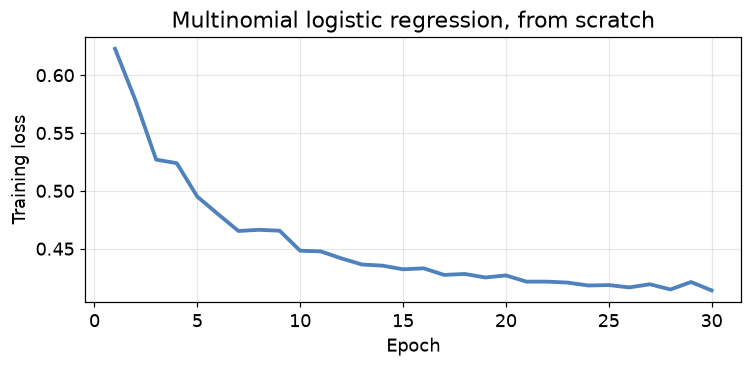

Dev macro-F1, from scratch:  0.703
Dev macro-F1, scikit-learn:  0.710
Same prediction on 98.7% of dev

negative  not, no, hours, delayed, worst, hold, cancelled, why, because, nothing
neutral   can, southwestair, jetblue, any, hi, united, number, dm, tomorrow, possible
positive  thanks, thank, great, awesome, amazing, love, best, thx, kudos, excellent


In [133]:
# ── Train the triage model from scratch ───────────────────────────────────────
def _reference_softmax_train(X, y, K=3, eta=1.0, epochs=20, batch_size=64, alpha=0.0, decay=0.0, seed=SEED):
    """Library stand-in for an unfinished Task 5 or 6."""
    clf = LogisticRegression(C=1 / (2 * alpha) if alpha > 0 else 1e6, max_iter=2000).fit(X, y)
    return clf.coef_, clf.intercept_, []

train_softmax_safe = with_fallback(6, train_softmax, _reference_softmax_train, "scikit-learn's LogisticRegression")


def predict_multi(X, W, b):
    return np.argmax(softmax_safe(X @ W.T + b), axis=1)


start = time.perf_counter()
W_tfidf, b_multi, hist_multi = train_softmax_safe(X_tr, y_tr_multi, eta=5.0, epochs=30, batch_size=64, alpha=ALPHA, decay=0.1)
print(f"From scratch: {time.perf_counter() - start:.1f} s")
if hist_multi:
    print(f"Loss: start log 3 = {np.log(3):.3f}, final = {hist_multi[-1]:.3f}")
    plt.figure(figsize=(7, 3.5))
    plt.plot(range(1, len(hist_multi) + 1), hist_multi, lw=2.5, color="#4f81bd")
    plt.xlabel("Epoch")
    plt.ylabel("Training loss")
    plt.title("Multinomial logistic regression, from scratch")
    plt.tight_layout()
    plt.show()

sk_multi = LogisticRegression(C=1 / (2 * ALPHA), max_iter=2000).fit(X_tr, y_tr_multi)
y_pred_multi = predict_multi(X_dv, W_tfidf, b_multi)
y_pred_sk = sk_multi.predict(X_dv)
print(f"Dev macro-F1, from scratch:  {f1_score(y_dv_multi, y_pred_multi, average='macro'):.3f}")
print(f"Dev macro-F1, scikit-learn:  {f1_score(y_dv_multi, y_pred_sk, average='macro'):.3f}")
print(f"Same prediction on {np.mean(y_pred_multi == y_pred_sk):.1%} of dev\n")

for k, label in enumerate(CLASSES):
    words = [vocab[j] for j in np.argsort(-W_tfidf[k]) if not display_rude(vocab[j])][:10]
    print(f"{label:<9} {', '.join(words)}")

**Why start at $\log 3$?** At all-zero parameters each of the three classes gets probability $1/3$, and $-\log(1/3)=1.099$.

---
## 8. Evaluation and the Alert Threshold

### Task 7 — Per-class metrics, macro and micro

The lecture slide lays out a confusion matrix with **system output in rows and gold labels in columns**, and we follow it. Careful: scikit-learn's `confusion_matrix` uses the opposite convention, with gold in rows.

$$\text{precision}_k=\frac{TP_k}{TP_k+FP_k}\qquad\text{recall}_k=\frac{TP_k}{TP_k+FN_k}\qquad F_1=\frac{2PR}{P+R}$$

**Why the harmonic mean?** It stays close to the lower of $P$ and $R$, so a model cannot hide weak recall behind strong precision.

**Task:** Complete two functions.

1. `per_class_prf(cm)`: precision, recall and $F_1$ per class. If a denominator is 0, the value is 0: a class the system never predicts has no precision to speak of.
2. `macro_micro(cm)`: **macro** averages the per-class values; **micro** pools all the counts into one table first.

**Hint:** $TP_k$ is the diagonal, `np.diag(cm)`. A row sum is everything the system called $k$; a column sum is everything truly $k$.

In [134]:
def confusion(y_gold, y_pred, K):
    """Confusion matrix in the slide 89 layout: rows = system output, columns = gold."""
    cm = np.zeros((K, K), dtype=int)
    for gold, pred in zip(y_gold, y_pred):
        cm[pred, gold] += 1
    return cm


def per_class_prf(cm):
    """Return (precision, recall, f1), each an array of shape [K].

    cm: [K × K] confusion matrix with rows = system output and columns = gold.
    """
    cm = np.asarray(cm, dtype=float)
    true_positives = np.diag(cm)
    false_positives = np.sum(cm, axis=1) - true_positives
    false_negatives = np.sum(cm, axis=0) - true_positives
    precision = np.divide(true_positives, true_positives + false_positives, out=np.zeros_like(true_positives), where=(true_positives + false_positives) != 0)
    recall = np.divide(true_positives, true_positives + false_negatives, out=np.zeros_like(true_positives), where=(true_positives + false_negatives) != 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(precision), where=(precision + recall) != 0)
    return precision, recall, f1


def macro_micro(cm):
    """Return a dict with keys macro_p, macro_r, macro_f1, micro_p, micro_r, micro_f1."""
    cm = np.asarray(cm, dtype=float)
    tp = np.diag(cm)
    fp = np.sum(cm, axis=1) - tp
    fn = np.sum(cm, axis=0) - tp
    f1 = np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros_like(tp), where=(2 * tp + fp + fn) != 0)
    macro_f1 = np.mean(f1)
    macro_p = np.mean(np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) != 0))
    macro_r = np.mean(np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) != 0)) 
     # Micro: pool the counts over all classes, then compute once
    micro_tp, micro_fp, micro_fn = tp.sum(), fp.sum(), fn.sum()
    micro_p = micro_tp / (micro_tp + micro_fp) if (micro_tp + micro_fp) != 0 else 0.0
    micro_r = micro_tp / (micro_tp + micro_fn) if (micro_tp + micro_fn) != 0 else 0.0
    micro_f1 = 2 * micro_p * micro_r / (micro_p + micro_r) if (micro_p + micro_r) != 0 else 0.0

    return {
        "macro_p": macro_p,
        "macro_r": macro_r,
        "macro_f1": macro_f1,
        "micro_p": micro_p,
        "micro_r": micro_r,
        "micro_f1": micro_f1
    }   


In [135]:
# ✅ Test — Task 7
# The slide 89 matrix. Rows: system says urgent, normal, spam. Columns: gold.
SLIDE_CM = np.array([[8, 10, 1], [5, 60, 50], [3, 30, 200]])

precision, recall, f1 = call_task(7, per_class_prf, SLIDE_CM)
assert not np.allclose(precision, [8/16, 60/100, 200/251]), "You swapped precision and recall. Rows are system output: a ROW sum is TP + FP."
assert np.allclose(precision, [8/19, 60/115, 200/233]), f"Precision should be [.42, .52, .86] (slide 90), got {np.round(precision, 2)}."
assert np.allclose(recall, [8/16, 60/100, 200/251]), f"Recall should be [.50, .60, .80] (slide 89), got {np.round(recall, 2)}."
assert np.allclose(f1, 2 * precision * recall / (precision + recall)), "F1 must be the harmonic mean 2PR / (P + R)."

zero_p, zero_r, zero_f = per_class_prf(np.array([[5, 1], [0, 0]]))
assert np.all(np.isfinite(zero_p)) and np.isclose(zero_p[1], 0.0) and np.isclose(zero_f[1], 0.0), "A class never predicted must get precision 0 and F1 0, not NaN. Guard against division by zero."

scores = call_task(7, macro_micro, SLIDE_CM)
assert np.isclose(scores["macro_p"], 0.60, atol=0.005), f"Macro precision should be .60 (slide 90), got {scores['macro_p']:.3f}."
assert np.isclose(scores["micro_p"], 268 / 367), f"Micro precision should be 268/367 = .73 (slide 90), got {scores['micro_p']:.3f}. Pool the counts first; do not average."
assert np.isclose(scores["macro_f1"], f1.mean()), "macro_f1 must be the mean of the per-class F1 values."
assert np.isclose(scores["micro_f1"], 268 / 367), f"micro_f1 should equal 268/367 here, got {scores['micro_f1']:.3f}."

# Must agree with scikit-learn on a random example.
rng = np.random.default_rng(3)
g, s = rng.integers(0, 3, 200), rng.integers(0, 3, 200)
cm_r = confusion(g, s, 3)
assert np.isclose(macro_micro(cm_r)["macro_f1"], f1_score(g, s, average="macro")), "macro_f1 disagrees with scikit-learn."
assert np.isclose(macro_micro(cm_r)["micro_f1"], f1_score(g, s, average="micro")), "micro_f1 disagrees with scikit-learn."
print("✅ Task 7 passed")

✅ Task 7 passed


In [136]:
# ── Fallbacks, then evaluate the triage model ─────────────────────────────────
def _expand(cm):
    """Turn a confusion matrix back into gold and predicted lists, for the library versions."""
    cm = np.asarray(cm, dtype=int)
    pred, gold = np.nonzero(cm)
    counts = cm[pred, gold]
    return np.repeat(gold, counts), np.repeat(pred, counts)

def _reference_prf(cm):
    gold, pred = _expand(cm)
    p, r, f, _ = precision_recall_fscore_support(gold, pred, labels=range(len(cm)), average=None, zero_division=0)
    return p, r, f

def _reference_macro_micro(cm):
    gold, pred = _expand(cm)
    out = {}
    for kind in ("macro", "micro"):
        out[f"{kind}_p"], out[f"{kind}_r"], out[f"{kind}_f1"], _ = precision_recall_fscore_support(
            gold, pred, labels=range(len(cm)), average=kind, zero_division=0)
    return out

per_class_prf_safe = with_fallback(7, per_class_prf, _reference_prf, "scikit-learn's metrics")
macro_micro_safe = with_fallback(7, macro_micro, _reference_macro_micro, "scikit-learn's metrics")

slide = macro_micro_safe(np.array([[8, 10, 1], [5, 60, 50], [3, 30, 200]]))
print(f"Slide 90: macro precision = {slide['macro_p']:.2f} (slide: .60), micro precision = {slide['micro_p']:.2f} (slide: .73)\n")

cm_dev = confusion(y_dv_multi, y_pred_multi, 3)
print(pd.DataFrame(cm_dev, index=[f"system {c}" for c in CLASSES], columns=[f"gold {c}" for c in CLASSES]), "\n")

p_k, r_k, f_k = per_class_prf_safe(cm_dev)
print(pd.DataFrame({"precision": p_k, "recall": r_k, "F1": f_k}, index=CLASSES).round(3), "\n")


# Compare with the useless model that always says "negative", and with class weights.
always_negative = np.zeros_like(y_dv_multi)
balanced = LogisticRegression(C=1 / (2 * ALPHA), class_weight="balanced", max_iter=2000).fit(X_tr, y_tr_multi)

print(f"{'Model':<34}{'accuracy':>10}{'micro-F1':>10}{'macro-F1':>10}")
for name, pred in [("Always 'negative'", always_negative), ("Softmax, from scratch", y_pred_multi),
                   ("scikit-learn, balanced classes", balanced.predict(X_dv))]:
    s = macro_micro_safe(confusion(y_dv_multi, pred, 3))
    print(f"{name:<34}{np.mean(pred == y_dv_multi):>10.3f}{s['micro_f1']:>10.3f}{s['macro_f1']:>10.3f}")

Slide 90: macro precision = 0.60 (slide: .60), micro precision = 0.73 (slide: .73)

                 gold negative  gold neutral  gold positive
system negative           1291           211             94
system neutral              59           226             58
system positive             12            21            189 

          precision  recall     F1
negative      0.809   0.948  0.873
neutral       0.659   0.493  0.564
positive      0.851   0.554  0.671 

Model                               accuracy  micro-F1  macro-F1
Always 'negative'                      0.630     0.630     0.258
Softmax, from scratch                  0.789     0.789     0.703
scikit-learn, balanced classes         0.763     0.763     0.712


**Why micro-F1 equals accuracy here.** Each message gets exactly one prediction, so every false positive for one class is a false negative for another. Pooled precision and pooled recall are then both just the share of correct predictions.

**Why macro and micro differ.** Micro is dominated by the frequent negative class. Macro gives each class one equal vote. Always saying "negative" scores 0.63 on accuracy and micro-F1, but only 0.26 on macro-F1, which exposes it. From the table, recall for the rare classes is much lower than for negative. Balancing the classes lowers accuracy (0.79 to 0.76) while raising macro-F1 (0.70 to 0.71).

**That is why the competition uses macro-F1.** A triage system that ignores thanks and questions is a poor product even if most messages are complaints.

**What is `class_weight="balanced"`?** It makes mistakes on rare classes cost more in the loss, in inverse proportion to class frequency. It usually trades some micro-F1 for macro-F1, which you may want to use in the competition.

### Task 8 — Where should the alert fire?

The manager writes: *"Each alert goes to a person. If too many are false alarms, the team will stop trusting the system. **At least 90% of alerts must be real complaints.** Within that limit, catch as many complaints as you can."*

Moving the threshold away from 0.5 trades one metric against the other: a higher threshold means more precision and less recall. This is a business decision, because the right balance depends on the cost of a missed complaint versus a wasted look.

**Task:** Complete `choose_threshold`. Try each distinct predicted probability as the threshold $t$, flagging a message when $\hat y\geq t$, and among those with precision at least `min_precision`, return one with the highest recall. If none qualifies, return `1.0`.

**Why choose this on dev?** The threshold is a hyperparameter too, and choosing it on test would be cheating.

**What a correct result looks like:** on our dev set, a threshold of about 0.69, with precision about 0.90 and recall about 0.77.

In [137]:
def choose_threshold(y_true, p, min_precision=0.9):
    """Return the threshold with the highest recall among those with precision >= min_precision.

    y_true: [m] labels 0 or 1    p: [m] predicted P(y=1|x)
    A message is flagged when p >= threshold. Return 1.0 if no threshold reaches min_precision.
    """
    y_true, p = np.asarray(y_true), np.asarray(p)
    # YOUR CODE HERE
    for threshold in np.unique(p):
        y_pred = (p >= threshold).astype(int)
        precision, recall, _, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
        if precision >= min_precision:
            return threshold
    return 1.0


In [138]:
# ✅ Test — Task 8
y_t = np.array([1, 1, 0, 1, 0, 1, 0, 0])
p_t = np.array([0.95, 0.9, 0.8, 0.7, 0.6, 0.4, 0.3, 0.1])

def _precision_recall(y, p, t):
    flagged = p >= t
    tp = np.sum(flagged & (y == 1))
    return tp / max(flagged.sum(), 1), tp / np.sum(y == 1)

t = call_task(8, choose_threshold, y_t, p_t, 0.7)
prec, rec = _precision_recall(y_t, p_t, t)
assert prec >= 0.7, f"Threshold {t} gives precision {prec:.2f}, below the required 0.70."
assert np.isclose(rec, 0.75), f"The best recall with precision >= 0.70 is 0.75, but threshold {t} gives {rec:.2f}. Flag with p >= t and keep the highest recall."

t = choose_threshold(y_t, p_t, 1.0)
assert np.isclose(_precision_recall(y_t, p_t, t)[1], 0.5), f"With precision 1.0 required, recall should be 0.50, but threshold {t} gives {_precision_recall(y_t, p_t, t)[1]:.2f}."

t = choose_threshold(np.array([0, 0, 0]), np.array([0.9, 0.5, 0.1]), 0.5)
assert np.isclose(t, 1.0), f"When no threshold reaches the required precision, return 1.0, got {t}."
print("✅ Task 8 passed")

✅ Task 8 passed


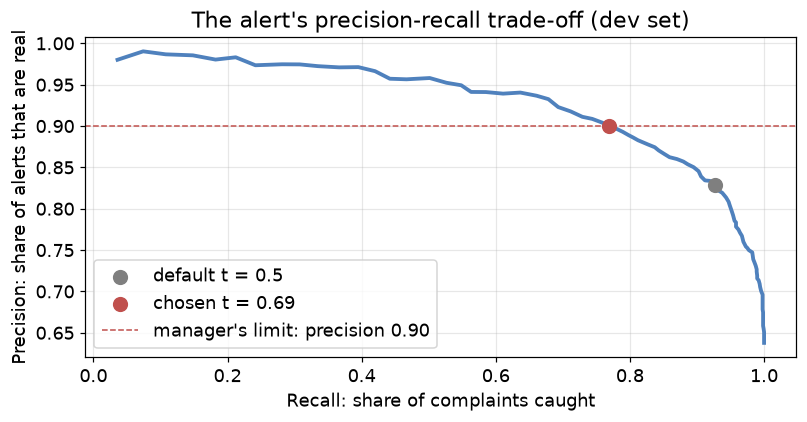

 threshold  precision   recall  alerts
      0.50      0.829    0.927    1523
      0.69      0.900    0.769    1164


In [139]:
# ── Fallback, then the business decision ──────────────────────────────────────
def _reference_threshold(y_true, p, min_precision=0.9):
    print("   (Using the default 0.5 decision boundary until you finish Task 8.)")
    return 0.5

choose_threshold_safe = with_fallback(8, choose_threshold, _reference_threshold, "the default threshold")

p_dv = sigmoid_safe(X_dv @ w_tfidf + b_tfidf)
chosen = choose_threshold_safe(y_dv, p_dv, 0.9)

def alert_report(t):
    flagged = p_dv >= t
    tp = np.sum(flagged & (y_dv == 1))
    return tp / max(flagged.sum(), 1), tp / y_dv.sum(), flagged.sum()

grid = np.linspace(0.02, 0.98, 97)
curve = np.array([alert_report(t)[:2] for t in grid])

plt.figure(figsize=(7.5, 4))
plt.plot(curve[:, 1], curve[:, 0], lw=2.5, color="#4f81bd")
for t, color, name in [(0.5, "#7f7f7f", "default t = 0.5"), (chosen, "#c0504d", f"chosen t = {chosen:.2f}")]:
    pr, rc, _ = alert_report(t)
    plt.scatter([rc], [pr], color=color, s=80, zorder=3, label=name)
plt.axhline(0.9, color="#c0504d", ls="--", lw=1, label="manager's limit: precision 0.90")
plt.xlabel("Recall: share of complaints caught")
plt.ylabel("Precision: share of alerts that are real")
plt.title("The alert's precision-recall trade-off (dev set)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"{'threshold':>10}{'precision':>11}{'recall':>9}{'alerts':>8}")
for t in [0.5, chosen]:
    pr, rc, n = alert_report(t)
    print(f"{t:>10.2f}{pr:>11.3f}{rc:>9.3f}{n:>8}")

**The decision.** At the default 0.5, only about 83% of alerts are real. Raising the threshold to about 0.69 meets the manager's 90% limit, cutting false alarms from about 260 to about 115 on dev. The price is real: recall falls from 0.93 to 0.77, so about 215 more complaints go unflagged. The model cannot decide whether that is worth it. Your job is to show the trade-off clearly so the business can choose. If missed complaints were costlier, as for safety issues, a lower threshold would be the right call.

---
## 9. Regularization
This section is a demonstration: read and run. In the deck regularization comes last, but we need it before we can tune with cross-validation in §10.*

A model **overfits** when it fits accidents of the training data, typically through very large weights. Regularization adds a penalty, with strength $\alpha$:

$$\text{L2: }\ \hat\theta=\underset{\theta}{\text{argmax}}\sum_{i=1}^{m}\log P(y^{(i)}|x^{(i)};\theta)-\alpha\sum_{j=1}^{n}\theta_j^2\qquad\text{L1: }\ \ldots-\alpha\sum_{j=1}^{n}|\theta_j|$$

Now you can read `apply_penalty` from §5. Our training minimises the *average* loss, so we divide the penalty by the number of training messages $m$ to keep the same balance as the slide:

- **L2:** the derivative of $\theta^2$ is $2\theta$, so each step does `w -= eta * 2 * alpha / m * w`. Large weights shrink the most.
- **L1:** the derivative of $|\theta|$ is $\pm1$, so each step moves every weight toward zero by the same fixed amount, `eta * alpha / m`. If that step would cross zero, we stop at exactly zero. This is why L1 gives truly sparse weights.

**Why is $b$ not penalized?** The bias only sets the base rate of the classes, and shrinking it would not make the model simpler.

**Why this range of $\alpha$?** It is the logarithmic grid. We do not know even the order of magnitude in advance.

α = 0.0001  train macro-F1 = 0.989   dev macro-F1 = 0.766   ‖w‖ = 966.4
α = 0.001   train macro-F1 = 0.983   dev macro-F1 = 0.779   ‖w‖ = 491.3
α = 0.01    train macro-F1 = 0.967   dev macro-F1 = 0.798   ‖w‖ = 207.7
α = 0.1     train macro-F1 = 0.921   dev macro-F1 = 0.820   ‖w‖ = 77.0
α = 1       train macro-F1 = 0.849   dev macro-F1 = 0.802   ‖w‖ = 25.8
α = 10      train macro-F1 = 0.673   dev macro-F1 = 0.661   ‖w‖ = 7.1
α = 100     train macro-F1 = 0.387   dev macro-F1 = 0.387   ‖w‖ = 1.1
(0.4 s)


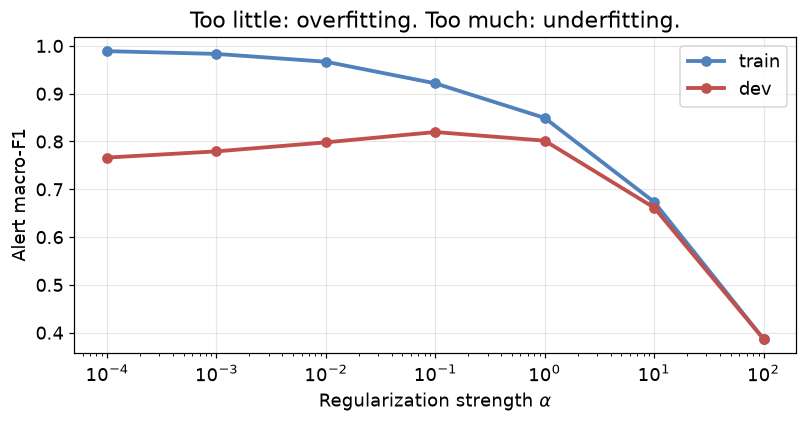

In [140]:
# ── Sweep alpha, L2 (slide 107 grid) ──────────────────────────────────────────
# We use scikit-learn here because overfitting only shows once training has fully converged.
# Our from-scratch loop stops after a fixed number of epochs, before the weights can grow very large.
alphas = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
train_scores, dev_scores, norms = [], [], []
start = time.perf_counter()
for a in alphas:
    clf = LogisticRegression(C=1 / (2 * a), max_iter=3000).fit(X_tr, y_tr)
    train_scores.append(f1_score(y_tr, clf.predict(X_tr), average="macro"))
    dev_scores.append(f1_score(y_dv, clf.predict(X_dv), average="macro"))
    norms.append(np.linalg.norm(clf.coef_))
    print(f"α = {a:<7} train macro-F1 = {train_scores[-1]:.3f}   dev macro-F1 = {dev_scores[-1]:.3f}   ‖w‖ = {norms[-1]:.1f}")
print(f"({time.perf_counter() - start:.1f} s)")

plt.figure(figsize=(7.5, 4))
plt.semilogx(alphas, train_scores, "o-", lw=2.5, color="#4f81bd", label="train")
plt.semilogx(alphas, dev_scores, "o-", lw=2.5, color="#c0504d", label="dev")
plt.xlabel(r"Regularization strength $\alpha$")
plt.ylabel("Alert macro-F1")
plt.title("Too little: overfitting. Too much: underfitting.")
plt.legend()
plt.tight_layout()
plt.show()

**Reading the plot.** At very small α the model nearly memorises the training set (train 0.99) but dev is only 0.76: that gap is **overfitting**, and the weights are huge ($\|\mathbf{w}\|$ above 1000). At very large α the weights are crushed toward zero, and train and dev both collapse to 0.39: **underfitting**, as the model just predicts the majority class. Dev peaks in between, near α = 0.1.

| What you see | Diagnosis |
|---|---|
| Both scores improve together | Healthy learning |
| Train keeps improving while dev falls behind, with a large gap | Overfitting: increase α or simplify the features |
| Both scores are low and close together | Underfitting: decrease α or add richer features |

In [141]:
# ── L2 keeps every weight small; L1 removes weights entirely ──────────────────
print(f"{'penalty':<10}{'α':>6}{'dev macro-F1':>14}{'non-zero weights':>18}")
for pen, a in [("l2", 1.0), ("l1", 0.1), ("l1", 1.0), ("l1", 3.0)]:
    w_p, b_p, _ = train_safe(X_tr, y_tr, eta=5.0, epochs=30, batch_size=64, alpha=a, penalty=pen, decay=0.1)
    print(f"{pen:<10}{a:>6}{alert_f1(X_dv, y_dv, w_p, b_p):>14.3f}{np.sum(w_p != 0):>12,} of {len(w_p):,}")
print("\nWords L1 kept at α = 3:", ", ".join([vocab[j] for j in np.argsort(-np.abs(w_p)) if w_p[j] != 0 and not display_rude(vocab[j])][:15]))

penalty        α  dev macro-F1  non-zero weights
l2           1.0         0.800       5,105 of 5,105
l1           0.1         0.818       4,895 of 5,105
l1           1.0         0.793       2,477 of 5,105
l1           3.0         0.772       1,259 of 5,105

Words L1 kept at α = 3: thank, thanks, no, not, hours, southwestair, jetblue, delayed, hold, virginamerica, worst, great, cancelled, why, love


**L2 vs L1.** L2 keeps all 5,105 weights non-zero. As α grows, L1 sets more and more weights to exactly zero: at α = 3 it uses about a quarter of the vocabulary, and dev macro-F1 falls only from about 0.82 to 0.77. The surviving words are the sensible ones. This is what lecture slide means by L1 effectively reducing the number of features. With scikit-learn the correspondence for L1 is $C=1/\alpha$, since its L1 objective has no $\frac{1}{2}$ in front of the penalty.

---
## 10. Dev Sets and Cross-Validation

**Why three splits?** We train on `train`, tune on `dev`, and judge once on `test`. If we tuned on test, the test score would stop being an honest estimate.

A single dev set can still be small or unrepresentative. In **$k$-fold cross-validation** we split the training set into $k$ folds, train on $k-1$, validate on the one left out, rotate, and average. As advises, the test set stays apart, so we can still inspect the training data freely.

**How the choice is made:** each candidate $\alpha$ is evaluated across all folds, the candidate with the best *average* wins, and then one final model is trained on the whole training set.

**Why 5 folds?** Five keeps this cell short in class and each fold still trains on 80% of the data. **Why stratified?** Each fold keeps the class proportions, which matters with a smallest class of 16%. **Why refit TF-IDF inside each fold?** The left-out fold must be truly unseen, including its vocabulary.

α = 0.0001  (C = 5000    ) mean macro-F1 = 0.695 ± 0.012
α = 0.001   (C = 500     ) mean macro-F1 = 0.696 ± 0.008
α = 0.01    (C = 50      ) mean macro-F1 = 0.704 ± 0.009
α = 0.1     (C = 5       ) mean macro-F1 = 0.716 ± 0.009
α = 1       (C = 0.5     ) mean macro-F1 = 0.721 ± 0.011
α = 10      (C = 0.05    ) mean macro-F1 = 0.693 ± 0.008
α = 100     (C = 0.005   ) mean macro-F1 = 0.662 ± 0.010
(4.7 s)

Chosen: α = 1


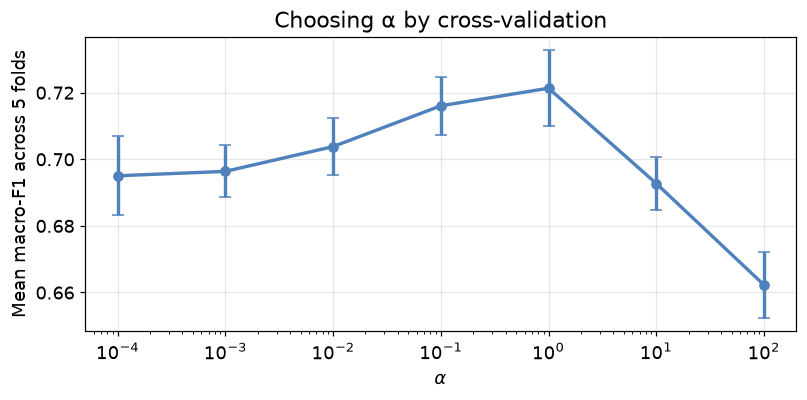

Final model, dev macro-F1: 0.706


In [142]:
# ── 5-fold cross-validation to choose alpha for the triage model ──────────────
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
texts = train["text"].to_numpy()
cv_mean, cv_std = [], []

start = time.perf_counter()
for a in alphas:
    fold_scores = []
    for fit_idx, val_idx in folds.split(texts, y_tr_multi):
        model = make_pipeline(TfidfVectorizer(min_df=2),
                              LogisticRegression(C=1 / (2 * a), class_weight="balanced", max_iter=300, tol=1e-3))
        model.fit(texts[fit_idx], y_tr_multi[fit_idx])
        fold_scores.append(f1_score(y_tr_multi[val_idx], model.predict(texts[val_idx]), average="macro"))
    cv_mean.append(np.mean(fold_scores))
    cv_std.append(np.std(fold_scores))
    print(f"α = {a:<7} (C = {1 / (2 * a):<8.4g}) mean macro-F1 = {cv_mean[-1]:.3f} ± {cv_std[-1]:.3f}")
print(f"({time.perf_counter() - start:.1f} s)")

best_alpha = alphas[int(np.argmax(cv_mean))]
print(f"\nChosen: α = {best_alpha}")

plt.figure(figsize=(7.5, 3.8))
plt.errorbar(alphas, cv_mean, yerr=cv_std, fmt="o-", lw=2.2, capsize=4, color="#4f81bd")
plt.xscale("log")
plt.xlabel(r"$\alpha$")
plt.ylabel("Mean macro-F1 across 5 folds")
plt.title("Choosing α by cross-validation")
plt.tight_layout()
plt.show()

# The final model: the chosen alpha, the whole training set, then one look at dev.
final_model = make_pipeline(TfidfVectorizer(min_df=2),
                            LogisticRegression(C=1 / (2 * best_alpha), class_weight="balanced", max_iter=2000))
final_model.fit(texts, y_tr_multi)
final_dev_f1 = f1_score(y_dv_multi, final_model.predict(dev["text"]), average="macro")
print(f"Final model, dev macro-F1: {final_dev_f1:.3f}")

---
## 11. Avoiding Harms
This section is a demonstration: read, run and discuss.*

Your manager asks: *"Before launch, does the model treat customers differently for no good reason?"* Lecture slide describes Kiritchenko and Mohammad (2018), who tested sentiment systems on sentence pairs identical except for a name. We can run a small version of the same audit.

**Why templates?** Only the name changes in each pair, so any change in the prediction must come from the name.

In [143]:
# ── Audit 1: does a person's name change the prediction? ──────────────────────
# First names following the slide 100 study; the Arabic names are added for our own context.
NAMES = ["Shaniqua", "Stephanie", "Ebony", "Amanda", "Jamal", "Adam", "Ahmed", "Fatima", "David", "Sarah"]
TEMPLATES = ["I talked to {} yesterday",
             "{} helped me at the gate today",
             "{} is waiting for a flight"]

known = set(vocab)
negative_col = list(final_model.classes_).index(0)
rows = {name: [final_model.predict_proba([t.format(name)])[0, negative_col] for t in TEMPLATES] for name in NAMES}
audit = pd.DataFrame(rows, index=TEMPLATES).T
audit["in vocabulary?"] = [name.lower() in known for name in NAMES]
print("P(negative) for each name and template:\n")
print(audit.round(3).to_string())
print(f"\nLargest gap between names, per template: {audit[TEMPLATES].max().sub(audit[TEMPLATES].min()).round(3).tolist()}")

P(negative) for each name and template:

           I talked to {} yesterday  {} helped me at the gate today  {} is waiting for a flight  in vocabulary?
Shaniqua                      0.302                           0.283                       0.733           False
Stephanie                     0.302                           0.283                       0.733           False
Ebony                         0.302                           0.283                       0.733           False
Amanda                        0.302                           0.283                       0.733           False
Jamal                         0.302                           0.283                       0.733           False
Adam                          0.302                           0.283                       0.733           False
Ahmed                         0.302                           0.283                       0.733           False
Fatima                        0.302                           0

**What we found.** For nine of the ten names, all predictions are *identical*, including the slide's pair. This is not evidence of fairness. Those names were dropped from the vocabulary, because they appear in fewer than two training messages, so the model literally cannot see them.

"David" is the exception: it appears in seven training tweets, only one of them negative, and that shifts P(negative) by up to 0.26 on the third template. A handful of messages about one person changed how the model treats everyone with that name. The lesson is the slide's: the model reproduces accidents in its training data. And since the system would behave differently if trained on more data with more names, this check has to be repeated for every new model version. Note also that P(negative) depends a lot on the wording of the template: "{} is waiting for a flight" scores high for nearly every name because of its other words, before any name is involved.

In [144]:
# ── Audit 2: does the airline's name change the prediction? ───────────────────
HANDLES = {"@united": "United", "@USAirways": "US Airways", "@AmericanAir": "American",
           "@SouthwestAir": "Southwest", "@JetBlue": "JetBlue", "@VirginAmerica": "Virgin America"}
neutral_message = "{} what time does the flight leave today"
swap = {name: final_model.predict_proba([neutral_message.format(handle)])[0, negative_col]
        for handle, name in HANDLES.items()}
print("Same neutral question, only the airline changes. P(negative):")
for name, value in sorted(swap.items(), key=lambda item: -item[1]):
    print(f"  {name:<16} {value:.3f}")


# ── Performance across groups (slide 104 asks model cards to report this) ─────
def airline_of(text):
    lowered = text.lower()
    for handle, name in HANDLES.items():
        if handle.lower() in lowered:
            return name
    return "other"

groups = dev["text"].map(airline_of)
pred_final = final_model.predict(dev["text"])
print(f"\n{'Airline':<16}{'messages':>9}{'% negative':>12}{'macro-F1':>10}")
for name in HANDLES.values():
    mask = (groups == name).to_numpy()
    print(f"{name:<16}{mask.sum():>9}{np.mean(y_dv_multi[mask] == 0):>12.0%}{f1_score(y_dv_multi[mask], pred_final[mask], average='macro'):>10.3f}")

Same neutral question, only the airline changes. P(negative):
  US Airways       0.236
  United           0.172
  American         0.166
  Southwest        0.099
  JetBlue          0.092
  Virgin America   0.084

Airline          messages  % negative  macro-F1
United                579         70%     0.649
US Airways            444         75%     0.694
American              378         74%     0.716
Southwest             359         48%     0.707
JetBlue               322         45%     0.687
Virgin America         79         34%     0.788


**What we found.** The same neutral question gets a P(negative) of about 0.24 when addressed to US Airways and about 0.08 for Virgin America. In the data, 75% of messages to US Airways are negative compared with 34% for Virgin America, and the model absorbed that as evidence. Customers of one airline therefore start with a built-in suspicion of being negative, regardless of what they wrote. Macro-F1 also varies by airline, from about 0.65 to 0.79, though the Virgin America group has only 79 messages, so its score is uncertain.

This is the mechanism behind the harms: bias in the data becomes bias in the model. Lecture slide says there is no general fix, but we can test and document. For this model one might try replacing `@handles` with a single token, and then measure what that changes.

### A short model card

Lecture slide says that a model should be released with documentation of how it was built and where it should be used.

In [145]:
# ── Model card ────────────────────────────────────────────────────────────────
card = {
    "Algorithm": f"Multinomial logistic regression, L2, α = {best_alpha}, balanced class weights (scikit-learn)",
    "Training data": "US airline tweets, Feb 2015; duplicates removed; 10,084 messages",
    "Features": "TF-IDF of single words, min_df = 2, fitted on train only",
    "Evaluation": f"Dev macro-F1 = {final_dev_f1:.3f}; the alpha was chosen by 5-fold cross-validation",
    "Intended use": "Sorting airline customer messages for human follow-up",
    "Not intended for": "Other domains, or any decision about a person without human review",
    "Known limits": "Learns airline identity as a signal; noisy labels; US English tweets from 2015 only",
}
for key, value in card.items():
    print(f"{key:<18} {value}")

Algorithm          Multinomial logistic regression, L2, α = 1, balanced class weights (scikit-learn)
Training data      US airline tweets, Feb 2015; duplicates removed; 10,084 messages
Features           TF-IDF of single words, min_df = 2, fitted on train only
Evaluation         Dev macro-F1 = 0.706; the alpha was chosen by 5-fold cross-validation
Intended use       Sorting airline customer messages for human follow-up
Not intended for   Other domains, or any decision about a person without human review
Known limits       Learns airline identity as a signal; noisy labels; US English tweets from 2015 only


---
## 12. 🏆 Team Competition

The manager wants the best triage model possible, and you are competing for it. **Beat the instructor's baseline:**

| | macro-F1 |
|---|---|
| Starter model below (dev) | **0.704** |
| Instructor's baseline (dev) | **0.743** |
| Instructor's baseline (hidden test) | **0.766** |

**Rules**

- **Logistic regression only**, binary or multinomial, with any regularization.
- **Any features built from the text:** word or character n-grams (recall the N-gram lab), TF-IDF variants, stemming, regex-based or hand-crafted features, or combinations.
- **Tune on train and dev only.** You may retrain on train + dev once your choices are final.
- **Not allowed:** pretrained language models, or external labelled data. This dataset is public, so please do not look up the test labels; that would only make your score meaningless.

**Why macro-F1?** Every class counts equally, so you cannot win by ignoring the rare ones (§8). **Why is the test set hidden?** So that the ranking reflects how your model handles messages it has never seen.

**Ideas to try:** `ngram_range=(1, 2)`, `sublinear_tf=True`, `analyzer="char_wb"`, `class_weight="balanced"`, different `C` values, replacing `@handles` with one token, your six features from §1 combined with TF-IDF, and the errors from §6 as a source of new features.

**Differences of about 0.01 between teams may just be noise:** the test set has 2,161 messages and some labels are themselves uncertain.

### Task 9 — Your model

**Task:** Complete `build_team_model` so that it returns your team name and an unfitted model. Any scikit-learn pipeline that takes raw text works, such as `make_pipeline(TfidfVectorizer(...), LogisticRegression(...))`, or `make_union(...)` to combine several vectorizers. The cells below train it, score it on dev and write your submission.

In [146]:
def build_team_model():
    """Return (team_name, model). The model is unfitted, and takes raw text in fit and predict."""

    # ── Line 1 of 12 ──
    # Define a helper function called normalise that takes one argument, text (one raw message).
    # Lines 2 to 5 are its body, so indent them one level deeper.
    def normalise(text):
        message = text.lower()  # Convert the text to lowercase
        message = re.sub(r'http[s]?://\S+', ' URL ', message)   
        message = re.sub(r'@\w+', ' @USER ', message)
        return message



    words = TfidfVectorizer(preprocessor=normalise, ngram_range=(1, 2), sublinear_tf=True,
                            token_pattern=r"(?u)\b[\w']+\b|[!?]")

    # Create the variable chars, a TfidfVectorizer for CHARACTER features.
    chars = TfidfVectorizer(preprocessor=normalise, analyzer="char_wb", ngram_range=(2, 5),
                            sublinear_tf=True, min_df=2)


    # Create the variable model with make_pipeline.
    # Its first step is make_union(words, chars), which builds both feature sets side by side
    union = make_union(words, chars)
    classifier = LogisticRegression(C=3, class_weight="balanced", max_iter=3000)
    return "Rayyan And Ameer's Team", make_pipeline(union, classifier)


In [147]:
# ── Submission helper: this writes the exact format the leaderboard expects ───
def make_submission(team_name, predictions):
    """Write submissions/<team_name>.csv with columns id,label, one row per test message."""
    predictions = list(predictions)
    if len(predictions) != len(test_public):
        raise ValueError(f"Expected {len(test_public)} predictions, got {len(predictions)}.")
    labels = [CLASSES[p] if not isinstance(p, str) else p for p in predictions]
    unknown = set(labels) - set(CLASSES)
    if unknown:
        raise ValueError(f"Unknown labels: {unknown}. Use {CLASSES}.")
    safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", team_name).strip("_")
    if not safe_name:
        raise ValueError("The team name must contain letters or digits.")
    Path("submissions").mkdir(exist_ok=True)
    path = Path("submissions") / f"{safe_name}.csv"
    pd.DataFrame({"id": test_public["id"], "label": labels}).to_csv(path, index=False)
    print(f"Wrote {path} with {len(labels)} predictions.")
    return path


# ── Train, score on dev, and submit ───────────────────────────────────────────
starter = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=2000))
starter.fit(train["text"], y_tr_multi)
print(f"Starter model, dev macro-F1: {f1_score(y_dv_multi, starter.predict(dev['text']), average='macro'):.3f}")

try:
    team_name, team_model = build_team_model()
except NotImplementedError:
    team_name, team_model = None, None
    print("⚠️  Task 9 is not finished yet: no submission written.")

submission_path = None
if team_model is not None:
    start = time.perf_counter()
    team_model.fit(train["text"], y_tr_multi)
    team_dev_f1 = f1_score(y_dv_multi, team_model.predict(dev["text"]), average="macro")
    print(f"Team '{team_name}', dev macro-F1: {team_dev_f1:.3f}   ({time.perf_counter() - start:.1f} s)")

    # Your choices are final at this point, so use all labelled data for the final fit.
    team_model.fit(pd.concat([train["text"], dev["text"]]), np.r_[y_tr_multi, y_dv_multi])
    submission_path = make_submission(team_name, team_model.predict(test_public["text"]))

Starter model, dev macro-F1: 0.704
Team 'Rayyan And Ameer's Team', dev macro-F1: 0.751   (5.5 s)
Wrote submissions/Rayyan_And_Ameer_s_Team.csv with 2161 predictions.


In [148]:
# ✅ Test — Task 9
assert team_model is not None, "Task 9 is not finished yet. Complete build_team_model, re-run its cell and the cell above, then re-run this test."
assert team_name and team_name != "your_team_name", "Please give your team a real name."
assert submission_path is not None and submission_path.exists(), "The submission file was not written. Re-run the cell above."
sub = pd.read_csv(submission_path)
assert list(sub.columns) == ["id", "label"], f"The submission must have columns id,label, not {list(sub.columns)}."
assert len(sub) == len(test_public) and set(sub["id"]) == set(test_public["id"]), "The submission must have one row per test message."
assert set(sub["label"]) <= set(CLASSES), f"Labels must be from {CLASSES}."
assert len(set(sub["label"])) == 3, "Your model never predicts one of the classes, so its macro-F1 will suffer. Try class_weight='balanced'."
assert team_dev_f1 > 0.5, f"Dev macro-F1 is only {team_dev_f1:.3f}. Check that the model trains on the right labels."
print(f"✅ Task 9 passed: send {submission_path} to your instructor.")

✅ Task 9 passed: send submissions/Rayyan_And_Ameer_s_Team.csv to your instructor.


---
## Summary

| Idea | The one-line version |
|---|---|
| Sigmoid | Turns any score into a probability |
| Cross-entropy | Punishes confident mistakes hardest, and is convex for logistic regression |
| Gradient | (prediction − truth) × input; check it with finite differences |
| Mini-batch | The practical compromise between noisy SGD and slow batch training |
| Softmax | The same recipe with one weight vector per class |
| Macro vs micro | Macro gives each class one vote; micro is dominated by frequent classes |
| Threshold | A business decision that trades precision against recall |
| Regularization | L2 shrinks weights, L1 removes them; tune α by cross-validation |
| Harms | Audit your model: it learns whatever patterns its data contains |

**Next:** the slides note that logistic regression is the foundation of neural networks, which you will meet in a later chapter.

**Data:** Twitter US Airline Sentiment (Crowdflower / Figure Eight), CC BY-NC-SA 4.0. See `data/README.md`.